# Un modèle de décision typé entraîné pour la calibration (joey-1) rattrape-t-il un classifieur CamemBERT bien réglé sur des intentions françaises hiérarchisées ?

> **En bref.** Le zéro-shot ne rattrape pas un CamemBERT bien réglé sur ces intentions françaises ; il pourrait servir de premier tri sous seuil, mais sa calibration et son coût restent à valider sur données internes. macro-F1 (classe fine) : 0,706 [0,653 ; 0,769] pour Décision typée hiérarchique (baselabs/joey-1), contre 0,808 [0,765 ; 0,871] pour CamemBERT-base fine-tuné (404 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | En zéro-shot, avec décision hiérarchique (scénario puis intention) et moyenne sur deux ordres d'options, joey-1 atteint un macro-F1 à moins de 5 points d'un CamemBERT-base fine-tuné correctement (10 époques, sélection sur validation), avec une ECE < 0,05 après recalibration, un accord > 90 % sous permutation des options et des erreurs de parent < 20 %. |
| **Référence** | CamemBERT-base fine-tuné (réglé) — Classifieur à tête linéaire sur 60 intentions, entraîné plus longtemps que dans l'expérience antérieure, avec sélection de l'époque sur la validation et recalibration par température. |
| **Nouvelle approche** | joey-1 décision typée hiérarchique — Modèle de décision de 2 Md (post-entraîné de Qwen3.5-2B) qui rend une probabilité par option en une passe ; interrogé en deux questions de choix : scénario puis intention parmi les enfants, probabilités multipliées, moyennées sur deux ordres d'options. |
| **Données publiques** | [`mteb/amazon_massive_intent`](https://huggingface.co/datasets/mteb/amazon_massive_intent) (fr) |
| **Métrique principale** | macro-F1 (classe fine) (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `fingerprint` | Empreinte courte (sha256) d'un jeu de données, pour la traçabilité des résultats. |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'reason': 'reason', 'sub_reason': 'sub_reason', 'reason_description': 'reason_description', 'received_at': 'received_at', 'channel': 'channel'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen3-0.6B', 'almanach/camembert-base'], 'full': ['almanach/camembert-base', 'baselabs/joey-1']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['accelerate==1.15.0', 'flash-linear-attention==0.5.2', 'jinja2', 'pydantic', 'transformers==5.19.0']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Pour classer un message entrant (d'abord le **motif**, puis le **sous-motif**), deux familles d'outils s'opposent :
- le **classifieur fine-tuné** (ici CamemBERT-base) : rapide et précis, mais il faut des exemples annotés pour chaque classe ;
- le **modèle de décision typé** (ici joey-1, 2 à 3 Md de paramètres, licence MIT) : il ne rédige aucun texte. Il rend directement **une probabilité par option** d'une question à choix, sans entraînement sur nos classes.

L'éditeur annonce des probabilités *calibrées* (l'entraînement ajoute un terme de Brier), mais il n'en publie aucune mesure, et le modèle n'est documenté qu'en anglais. **En zéro-shot, sur des intentions françaises organisées en arbre, joey-1 approche-t-il un CamemBERT bien réglé ?**

### L'idée, en image
Au lieu de demander à un rédacteur une réponse qu'il faudra relire, on tend au modèle un **formulaire à cases**, et il coche chaque case avec un degré de certitude :
1. question 1 (*choix*) : « quel est le motif ? », parmi tous les motifs parents ;
2. question 2 (*choix*) : « quelle demande précise ? », parmi les enfants des motifs probables ;
3. on combine : $P(\text{intention}) = P(\text{motif}) \times P(\text{intention} \mid \text{motif})$ ;
4. chaque question est posée avec les options dans deux ordres (direct et inversé), puis on fait la moyenne pour neutraliser un **biais de position** ;
5. une **température** par niveau, ajustée sur la validation, recalibre les probabilités.

### Ce que la comparaison permet de décider
Hypothèse testée : un macro-F1 à moins de 5 points de CamemBERT, une ECE < 0,05 après recalibration, un accord > 90 % quand on permute les options et moins de 20 % d'erreurs de motif parent.
- Si elle tient, un modèle **sans données annotées** peut servir de premier tri, avec un seuil d'escalade vers un humain.
- Sinon, le classifieur fine-tuné reste la voie à privilégier, et l'on sait sur quel critère (justesse, calibration ou stabilité) le modèle de décision échoue.

## 2. Les données

### Tailles d'échantillon et règles communes
On fixe d'abord la taille des trois parties, puis deux règles valables dans les deux phases :
- **tirage stratifié** : chaque classe garde sa proportion réelle, ce qui est indispensable pour que l'ECE reste interprétable ;
- une classe absente de l'entraînement est retirée de la validation et du test, car CamemBERT ne pourrait pas la prédire.

La graine commune `SEED` fixe tous les tirages. À l'échelle réduite, 110 messages de test sont prévus et la boucle du modèle de décision s'arrête à 100, le minimum exigé : on exerce ainsi l'arrêt anticipé dès cette échelle.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

TRAIN_SIZE = sample_size(reduced=1000, full=None)      # énoncés d'entraînement de la référence (None = tout)
VALIDATION_SIZE = sample_size(reduced=300, full=None)  # choix de l'époque et des températures
TEST_SIZE = sample_size(reduced=110, full=1500)        # énoncés prévus, communs aux deux approches (>= 100)


def sample_rows(frame: pd.DataFrame, size: int | None) -> pd.DataFrame:
    """Tire `size` lignes avec la graine, stratifiées par classe si possible (None = toutes les lignes)."""
    if size is None or size >= len(frame):
        return frame.reset_index(drop=True)
    counts = frame["label"].value_counts()
    # La stratification exige au moins 2 exemples par classe et assez de place des deux côtés.
    can_stratify = counts.min() >= 2 and size >= len(counts) and len(frame) - size >= len(counts)
    sample, _ = train_test_split(frame, train_size=size, random_state=SEED,
                                 stratify=frame["label"] if can_stratify else None)
    return sample.reset_index(drop=True)


def finalize_splits(train_df: pd.DataFrame, validation_df: pd.DataFrame, test_df: pd.DataFrame):
    """Échantillonne les trois parties ; retire de la validation et du test les classes inconnues à l'entraînement."""
    train_df = sample_rows(train_df, TRAIN_SIZE)
    known_labels = set(train_df["label"])
    kept_parts = []
    for name, frame, size in (("validation", validation_df, VALIDATION_SIZE), ("test", test_df, TEST_SIZE)):
        kept = frame[frame["label"].isin(known_labels)]
        if len(kept) < len(frame):
            print(f"{name} : {len(frame) - len(kept)} lignes retirées (classe absente de l'entraînement)")
        kept_parts.append(sample_rows(kept, size))
    return train_df, kept_parts[0], kept_parts[1]

### Chargement de MASSIVE en français
**MASSIVE** réunit des énoncés courts adressés à un assistant vocal. Il compte **60 intentions** de la forme `scénario_intention` (par exemple `alarm_set`).
- Le **motif parent** est le préfixe placé avant le premier « _ » (`alarm`). On obtient un arbre à deux niveaux : 18 motifs, puis 1 à 9 enfants par motif.
- Le modèle de décision reçoit des **libellés lisibles** : l'enfant `alarm_set` devient « set » dans le motif « alarm ». Ces libellés restent en anglais, alors que les messages sont en français.

In [7]:
def load_public_split(dataset, split: str) -> pd.DataFrame:
    """Met une partie de MASSIVE au format commun : texte, intention (`label`) et motif parent."""
    raw = dataset[split].to_pandas()
    if "lang" in raw.columns:
        raw = raw[raw["lang"].astype(str).str.startswith("fr")]
    frame = pd.DataFrame({"text": raw["text"].astype(str).str.strip(),
                          "label": raw["label_text"].astype(str).str.strip()})
    frame = frame[frame["text"].str.len() > 0]
    # Le motif parent (scénario) est le préfixe de l'intention : « alarm_set » -> « alarm ».
    frame["parent"] = frame["label"].str.split("_", n=1).str[0]
    return frame.reset_index(drop=True)


if PHASE == "public":
    import datasets
    datasets.disable_progress_bars()
    massive = datasets.load_dataset("mteb/amazon_massive_intent", "fr")
    missing_columns = {"text", "label_text"} - set(massive["train"].column_names)
    assert not missing_columns, f"Colonnes manquantes : {missing_columns}"
    train, validation, test = finalize_splits(
        *(load_public_split(massive, split) for split in ("train", "validation", "test")))
    # Libellés lisibles posés au modèle de décision.
    class_display = {label: label.split("_", 1)[-1].replace("_", " ") for label in set(train["label"])}
    parent_display = {parent: parent for parent in set(train["parent"])}
    DATASET_INFO = {"name": "mteb/amazon_massive_intent", "config": "fr", "split": "test"}

README.md:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

train/fr.json.gz: reconstructing file:   0%|          |  0.00B /  211kB            

train/fr.json.gz: downloading bytes:           |  0.00B            

test/fr.json.gz: reconstructing file:   0%|          |  0.00B / 60.4kB            

test/fr.json.gz: downloading bytes:           |  0.00B            

validation/fr.json.gz: reconstructing file:   0%|          |  0.00B / 42.5kB            

validation/fr.json.gz: downloading bytes:           |  0.00B            

### Contrôles : effectifs et longueurs
Avant toute modélisation, on vérifie la taille de chaque partie, le nombre de classes et de motifs, l'effectif de la classe la plus rare et la longueur des messages en mots. Une classe trop rare au test rend son F1 très instable : il faut le savoir avant de lire le macro-F1.

In [8]:
def describe_splits(splits: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Tableau de contrôle : effectifs, classes, motifs et longueur des messages par partie."""
    rows = []
    for name, frame in splits.items():
        words = frame["text"].str.split().str.len()
        counts = frame["label"].value_counts()
        rows.append({"partie": name, "exemples": len(frame), "classes": frame["label"].nunique(),
                     "motifs parents": frame["parent"].nunique(), "min. par classe": int(counts.min()),
                     "max. par classe": int(counts.max()), "mots (médiane)": float(words.median()),
                     "mots (max.)": int(words.max())})
    return pd.DataFrame(rows).set_index("partie")


if PHASE == "public":
    display(describe_splits({"entraînement": train, "validation": validation, "test": test}))

,exemples,classes,motifs parents,min. par classe,max. par classe,mots (médiane),mots (max.)
partie,,,,,,,
entraînement,11514,60,18,4,810,7.0,37
validation,2033,59,18,2,131,7.0,29
test,1500,58,18,1,98,7.0,33


### Figure : répartition des motifs et longueur des messages
- À gauche, le nombre d'exemples d'entraînement par motif parent : un motif très fourni pèse lourd dans l'exactitude, mais pas dans le macro-F1, qui donne le même poids à chaque classe.
- À droite, la distribution des longueurs, en mots, pour l'entraînement et pour le test. Les deux courbes doivent se ressembler.

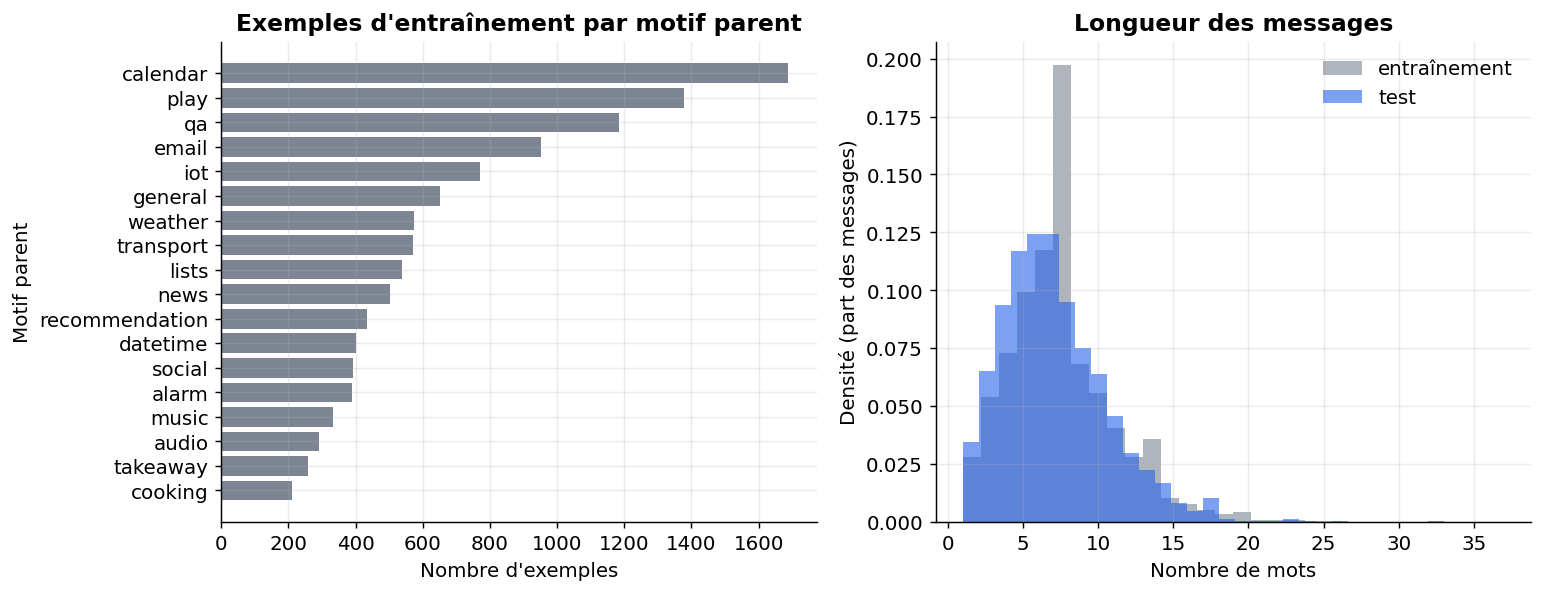

*Figure — À gauche, les effectifs d'entraînement par motif parent ; à droite, la distribution des longueurs en mots (entraînement et test). Des courbes proches signalent un test représentatif.*

In [9]:
def plot_data_overview(train_df: pd.DataFrame, test_df: pd.DataFrame) -> None:
    """Figure à deux panneaux : effectifs par motif parent et longueurs des messages."""
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 4.8))
    counts = train_df["parent"].value_counts().sort_values()
    ax_left.barh(counts.index, counts.values, color=COLORS["reference"])
    ax_left.set(title="Exemples d'entraînement par motif parent", xlabel="Nombre d'exemples",
                ylabel="Motif parent")
    for frame, name, color in ((train_df, "entraînement", COLORS["reference"]), (test_df, "test", COLORS["new"])):
        ax_right.hist(frame["text"].str.split().str.len(), bins=30, density=True, alpha=0.6,
                      color=color, label=name)
    ax_right.set(title="Longueur des messages", xlabel="Nombre de mots", ylabel="Densité (part des messages)")
    ax_right.legend()
    save_figure(fig, "data_overview",
                "À gauche, les effectifs d'entraînement par motif parent ; à droite, la distribution "
                "des longueurs en mots (entraînement et test). Des courbes proches signalent un test représentatif.")


if PHASE == "public":
    plot_data_overview(train, test)

### Quelques exemples
Quelques énoncés du test, avec leur intention et leur motif parent, pour se faire une idée de la tâche : des phrases très courtes, souvent sans ponctuation.

In [10]:
if PHASE == "public":
    preview(test, n=5)

### Colonnes attendues des données internes
Dans l'environnement cible, le jeu interne doit fournir ces six colonnes. La cellule `PRIVATE_CONFIG`, placée plus haut, fait correspondre ces noms à ceux du vrai fichier.
- `reason` et `sub_reason` donnent les deux niveaux de l'arbre ;
- `reason_description` fournit le libellé lisible posé au modèle de décision ;
- `received_at` permet un **découpage temporel** : on apprend sur le passé et on évalue sur la période la plus récente.

In [11]:
PRIVATE_COLUMNS = {
    "text": "Texte du message ou de l'e-mail, anonymisé",
    "reason": "Motif (niveau parent) validé",
    "sub_reason": "Sous-motif (niveau enfant) validé",
    "reason_description": "Libellé en clair et description de chaque classe, pour l'interrogation en langage naturel",
    "received_at": "Date de réception, pour le découpage temporel",
    "channel": "Canal (e-mail, chat, formulaire)",
}
FAKE_ROWS = 1200  # lignes factices : assez pour garder au moins 100 messages de test après nettoyage

### Une taxonomie factice pour vérifier le code
Pour tester la phase interne sans aucune donnée réelle, on décrit **4 motifs** (carte, virement, compte, accès) et **12 sous-motifs**. Chacun a une description et trois gabarits de message. Les gabarits contiennent des emplacements (`{amount}`, `{day}`) remplis au hasard, pour varier les textes.

In [12]:
FAKE_TAXONOMY = {  # (motif, sous-motif) : (description de la classe, gabarits séparés par « | »)
    ("carte", "opposition"): ("Opposition sur une carte de paiement perdue ou volée",
        "J'ai perdu ma carte de paiement {day}, pouvez-vous la bloquer ?|On m'a volé ma carte, je veux faire opposition au plus vite.|Ma carte a disparu depuis {day}, merci de la mettre en opposition."),
    ("carte", "plafond"): ("Modification du plafond de paiement ou de retrait",
        "Je voudrais augmenter le plafond de ma carte à {amount} € pour un achat.|Mon paiement de {amount} € a été refusé, le plafond est-il atteint ?|Est-il possible de relever temporairement mon plafond de retrait ?"),
    ("carte", "contestation"): ("Contestation d'une opération par carte non reconnue",
        "Je ne reconnais pas un paiement de {amount} € fait {day} avec ma carte.|Une opération de {amount} € apparaît sur mon relevé et je ne l'ai pas faite.|Je conteste un débit carte de {amount} €, que dois-je faire ?"),
    ("virement", "emission"): ("Aide pour émettre un virement ou ajouter un bénéficiaire",
        "Comment ajouter un nouveau bénéficiaire pour un virement ?|Je n'arrive pas à faire un virement de {amount} € depuis l'application.|Pouvez-vous m'aider à programmer un virement mensuel de {amount} € ?"),
    ("virement", "retard"): ("Virement émis ou attendu qui n'est pas arrivé",
        "Mon virement de {amount} € envoyé {day} n'est toujours pas arrivé.|J'attends un virement depuis {day}, pouvez-vous vérifier ?|Le destinataire n'a pas reçu les {amount} € que j'ai envoyés."),
    ("virement", "annulation"): ("Annulation ou rappel d'un virement",
        "Je me suis trompé de bénéficiaire, peut-on annuler le virement de {amount} € ?|Merci d'annuler le virement programmé pour {day}.|Est-il encore possible de rappeler un virement fait par erreur {day} ?"),
    ("compte", "releve"): ("Demande de relevé ou d'attestation de compte",
        "Pouvez-vous m'envoyer mon relevé de compte du mois dernier ?|J'ai besoin d'une attestation de compte pour mon employeur.|Je ne trouve plus mes relevés depuis {day} dans mon espace en ligne."),
    ("compte", "coordonnees"): ("Changement d'adresse, de téléphone ou d'e-mail",
        "Je déménage {day}, voici ma nouvelle adresse.|Merci de mettre à jour mon numéro de téléphone.|Comment changer l'adresse e-mail associée à mon compte ?"),
    ("compte", "cloture"): ("Demande de clôture de compte",
        "Je souhaite clôturer mon compte, quelle est la démarche ?|Merci de fermer mon compte et de virer le solde de {amount} €.|Je voudrais fermer mon compte avant {day}."),
    ("acces", "mot_de_passe"): ("Mot de passe oublié ou à réinitialiser",
        "J'ai oublié mon mot de passe, comment le réinitialiser ?|Mon code d'accès ne fonctionne plus depuis {day}.|Je ne reçois pas le lien de réinitialisation du mot de passe."),
    ("acces", "application"): ("Dysfonctionnement de l'application mobile",
        "L'application plante à chaque ouverture depuis {day}.|Impossible de me connecter à l'application, l'écran reste blanc.|Depuis la mise à jour de {day}, je ne vois plus mes opérations."),
    ("acces", "blocage"): ("Accès en ligne bloqué après plusieurs tentatives",
        "Mon accès en ligne est bloqué après trois essais.|Mon espace en ligne est verrouillé depuis {day}, pouvez-vous le débloquer ?|Je suis bloqué à l'étape de validation par SMS."),
}
DAYS = ["hier", "lundi", "ce matin", "la semaine dernière", "le 3 du mois", "vendredi"]
OPENINGS = ["Bonjour,", "Madame, Monsieur,", "Bonsoir,", ""]
CLOSINGS = ["Merci d'avance.", "Cordialement.", "Bonne journée.", "", "Merci de me répondre rapidement."]

### Générateur de données factices
`make_fake_data(n)` tire `n` messages. Les classes y ont des **fréquences inégales**, comme dans un flux réel. Les dates de réception couvrent une année et les canaux sont variés. Toutes les valeurs sont des scalaires simples, pour que l'aller-retour par fichier (CSV, parquet…) se passe sans perte.

In [13]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible, sans aucune donnée réelle, aux colonnes de PRIVATE_COLUMNS."""
    rng = np.random.default_rng(SEED)
    keys = list(FAKE_TAXONOMY)
    weights = rng.uniform(0.5, 1.5, size=len(keys))  # classes plus ou moins fréquentes
    start = pd.Timestamp("2025-01-01 08:00")
    rows = []
    for key_index in rng.choice(len(keys), size=n, p=weights / weights.sum()):
        reason, sub_reason = keys[key_index]
        description, templates = FAKE_TAXONOMY[(reason, sub_reason)]
        body = str(rng.choice(templates.split("|"))).format(
            amount=int(rng.integers(15, 2500)), day=str(rng.choice(DAYS)))
        parts = (str(rng.choice(OPENINGS)), body, str(rng.choice(CLOSINGS)))
        rows.append({
            "text": " ".join(part for part in parts if part),
            "reason": reason,
            "sub_reason": sub_reason,
            "reason_description": description,
            "received_at": (start + pd.Timedelta(minutes=int(rng.integers(0, 365 * 24 * 60)))).isoformat(),
            "channel": str(rng.choice(["e-mail", "chat", "formulaire"])),
        })
    return pd.DataFrame(rows)

### Nettoyage et découpage temporel
Le jeu est relu depuis un fichier, donc **tous les types sont convertis explicitement** (texte, date). On retire ensuite les messages vides, les doublons et les dates illisibles.
- L'étiquette complète est `motif / sous-motif`, et le parent est le motif.
- **Découpage temporel** : les 60 % les plus anciens servent à l'entraînement, les 20 % suivants à la validation, les 20 % les plus récents au test. On évite ainsi qu'un message du futur aide à classer le passé.

In [14]:
TRAIN_SHARE = 0.6        # part la plus ancienne : entraînement
VALIDATION_SHARE = 0.2   # période suivante : validation (le reste, le plus récent, sert au test)
MAX_LABEL_CHARS = 120    # longueur maximale d'un libellé posé au modèle de décision


def prepare_private_frame(raw: pd.DataFrame) -> pd.DataFrame:
    """Convertit les types, retire vides, doublons et dates illisibles, ajoute `label` et `parent`, trie par date."""
    def clean(column: str) -> pd.Series:
        """Colonne `column` en texte sans espaces de bord, les valeurs manquantes devenant des chaînes vides."""
        return raw[column].fillna("").astype(str).str.strip()

    frame = pd.DataFrame({"text": clean("text"), "reason": clean("reason"), "sub_reason": clean("sub_reason"),
                          "reason_description": clean("reason_description"), "channel": clean("channel"),
                          "received_at": pd.to_datetime(raw["received_at"], errors="coerce", utc=True)})
    n_raw = len(frame)
    frame = frame[(frame["text"] != "") & (frame["reason"] != "") & (frame["sub_reason"] != "")]
    frame = frame.drop_duplicates("text").dropna(subset=["received_at"]).copy()
    print(f"{n_raw - len(frame)} lignes retirées sur {n_raw} (vides, doublons ou date illisible)")
    frame["label"] = frame["reason"] + " / " + frame["sub_reason"]
    frame["parent"] = frame["reason"]
    # Tri stable par date puis par texte : le résultat ne dépend pas de l'ordre des lignes du fichier.
    return frame.sort_values(["received_at", "text"], kind="stable").reset_index(drop=True)


def temporal_split(frame: pd.DataFrame):
    """Découpe dans le temps : le passé pour apprendre, la période la plus récente pour évaluer."""
    first = int(len(frame) * TRAIN_SHARE)
    second = int(len(frame) * (TRAIN_SHARE + VALIDATION_SHARE))
    return frame.iloc[:first], frame.iloc[first:second], frame.iloc[second:]

### Chargement des données internes (phase `private` seulement)
`load_private_data` lit le jeu interne ou, faute de jeu, produit le jeu factice. On y applique ensuite **les mêmes transformations** qu'en phase publique : échantillonnage stratifié et libellés lisibles, pris dans `reason_description`. Seuls des agrégats sont affichés : effectifs, périodes et structure des colonnes.

In [15]:
if PHASE == "private":
    raw_private = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=FAKE_ROWS)
    private_frame = prepare_private_frame(raw_private)
    train, validation, test = finalize_splits(*temporal_split(private_frame))
    described = private_frame[private_frame["reason_description"] != ""]
    descriptions = described.groupby("label")["reason_description"].agg(lambda values: values.mode().iat[0])
    # Libellé posé au modèle : la description officielle, sinon le nom du sous-motif.
    class_display = {label: str(descriptions.get(label, label.split(" / ", 1)[-1]))[:MAX_LABEL_CHARS]
                     for label in set(train["label"])}
    parent_display = {parent: parent.replace("_", " ") for parent in set(train["parent"])}
    DATASET_INFO = {"name": "données internes", "config": fingerprint(private_frame[["text", "label"]]),
                    "split": "test (période la plus récente)"}
    splits = {"entraînement": train, "validation": validation, "test": test}
    display(describe_splits(splits))
    display(pd.DataFrame({name: {"début": frame["received_at"].min(), "fin": frame["received_at"].max()}
                          for name, frame in splits.items()}).T)
    preview(test)

### Arbre des classes (commun aux deux phases)
À partir de l'entraînement, on construit la liste des classes, celle des motifs parents et la table « motif → enfants ». Les deux approches utilisent **le même ordre de classes** : leurs matrices de probabilités ont ainsi les mêmes colonnes et se comparent directement.

In [16]:
classes = sorted(set(train["label"]))
class_index = {label: index for index, label in enumerate(classes)}
parent_of = train.drop_duplicates("label").set_index("label")["parent"].to_dict()
parents = sorted(set(parent_of.values()))
children_of = {parent: [label for label in classes if parent_of[label] == parent] for parent in parents}
class_parent_index = np.array([parents.index(parent_of[label]) for label in classes])  # motif de chaque classe

train_targets = train["label"].map(class_index).to_numpy()
validation_targets = validation["label"].map(class_index).to_numpy()
test_targets = test["label"].map(class_index).to_numpy()

print(f"{len(classes)} classes réparties en {len(parents)} motifs parents ; {len(test)} messages de test")
display(pd.DataFrame({"enfants": [len(children_of[parent]) for parent in parents]}, index=parents).T)

60 classes réparties en 18 motifs parents ; 1500 messages de test


,alarm,audio,calendar,cooking,datetime,email,general,iot,lists,music,news,play,qa,recommendation,social,takeaway,transport,weather
enfants,3,4,3,2,2,4,3,9,3,4,1,5,5,3,2,2,4,1


## 3. L'approche de référence

### Réglages de la référence : CamemBERT-base fine-tuné
La référence doit être **bien réglée**, sinon la comparaison avantage artificiellement le modèle zéro-shot. On reprend donc une recette classique pour un encodeur de taille « base » :
- taux d'apprentissage $5\cdot10^{-5}$, lots de 32, **warmup** de 10 % (le taux monte progressivement au début pour stabiliser l'entraînement) et décroissance des poids de 0,01 ;
- **10 époques** à l'échelle complète. On garde l'époque au meilleur macro-F1 de validation, ce qui évite à la fois le sous- et le sur-entraînement.

In [17]:
import gc
import shutil
import torch
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments)
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()  # masque l'avertissement attendu sur la tête non initialisée
transformers_logging.disable_progress_bar()  # pas de barres de progression au chargement des poids

REFERENCE_MODEL_ID = "almanach/camembert-base"
LEARNING_RATE = 5e-5                         # taux classique pour fine-tuner un encodeur « base »
EPOCHS = by_scale(reduced=1, full=10)        # 10 époques à l'échelle complète, meilleure retenue
BATCH_SIZE = 32                              # exemples par pas d'entraînement
WARMUP_SHARE = 0.1                           # part des pas où le taux monte progressivement
WEIGHT_DECAY = 0.01                          # régularisation légère des poids
MAX_LENGTH = by_scale(reduced=64, full=128)  # tokens par message (MASSIVE : bien en deçà)
EVAL_BATCH_SIZE = 64                         # lot d'inférence
LATENCY_SAMPLES = sample_size(reduced=50, full=300)  # messages chronométrés un par un
CHECKPOINT_DIR = Path(OUTPUT_DIR) / "camembert_checkpoints"

### Préparation des exemples et métrique de sélection
- `encode_texts` découpe les messages en tokens et y joint l'étiquette. Le **remplissage** (padding) est fait lot par lot, à la longueur du plus long message du lot, ce qui économise du calcul.
- `macro_f1_from_eval` calcule le macro-F1 de validation, qui sert à **choisir l'époque** : $F_1 = 2PR/(P+R)$ par classe (P = précision, R = rappel), puis moyenne simple sur les classes.

In [18]:
def encode_texts(tokenizer, texts, targets=None) -> list[dict]:
    """Tokenise les messages ; ajoute l'étiquette `labels` si elle est fournie (entraînement, validation)."""
    encoded = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)
    items = [{"input_ids": ids, "attention_mask": mask}
             for ids, mask in zip(encoded["input_ids"], encoded["attention_mask"])]
    if targets is not None:
        for item, target in zip(items, targets):
            item["labels"] = int(target)
    return items


def macro_f1_from_eval(eval_prediction) -> dict:
    """Macro-F1 de validation, utilisé par le Trainer pour retenir la meilleure époque."""
    logits, labels = eval_prediction
    return {"macro_f1": f1_score(labels, np.argmax(logits, axis=-1), average="macro", zero_division=0)}

### Entraînement
Le `Trainer` de `transformers` évalue le modèle à chaque époque, garde **le meilleur point de contrôle** au sens du macro-F1 de validation et le recharge à la fin. Sur GPU, l'entraînement passe en **précision mixte** (`fp16`), plus rapide et plus économe en mémoire. Le tableau affiché retrace la validation époque par époque.

In [19]:
set_seed(SEED)
reference_tokenizer = AutoTokenizer.from_pretrained(model_path(REFERENCE_MODEL_ID))
reference_model = AutoModelForSequenceClassification.from_pretrained(
    model_path(REFERENCE_MODEL_ID), num_labels=len(classes),
    id2label=dict(enumerate(classes)), label2id=class_index)
steps_per_epoch = int(np.ceil(len(train) / BATCH_SIZE))
training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR), learning_rate=LEARNING_RATE, num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
    warmup_steps=int(WARMUP_SHARE * steps_per_epoch * EPOCHS), weight_decay=WEIGHT_DECAY,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1, save_only_model=True,
    load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
    fp16=device() == "cuda", dataloader_pin_memory=device() == "cuda",
    logging_strategy="no", report_to="none", disable_tqdm=True, seed=SEED, data_seed=SEED)
trainer = Trainer(
    model=reference_model, args=training_args,
    train_dataset=encode_texts(reference_tokenizer, train["text"], train_targets),
    eval_dataset=encode_texts(reference_tokenizer, validation["text"], validation_targets),
    data_collator=DataCollatorWithPadding(reference_tokenizer), compute_metrics=macro_f1_from_eval)
trainer.train()

history = pd.DataFrame([log for log in trainer.state.log_history if "eval_macro_f1" in log])
history = history[["epoch", "eval_loss", "eval_macro_f1"]].rename(
    columns={"epoch": "époque", "eval_loss": "perte de validation", "eval_macro_f1": "macro-F1 de validation"})
best_epoch = int(round(history.loc[history["macro-F1 de validation"].idxmax(), "époque"]))
display(history.round(4).set_index("époque"))
print(f"Époque retenue : {best_epoch} (modèle {REFERENCE_MODEL_ID})")

{'eval_loss': '2.459', 'eval_macro_f1': '0.3274', 'eval_runtime': '0.8113', 'eval_samples_per_second': '2506', 'eval_steps_per_second': '39.44', 'epoch': '1'}


{'eval_loss': '1.225', 'eval_macro_f1': '0.5411', 'eval_runtime': '0.7737', 'eval_samples_per_second': '2628', 'eval_steps_per_second': '41.36', 'epoch': '2'}


{'eval_loss': '0.8441', 'eval_macro_f1': '0.6889', 'eval_runtime': '0.8078', 'eval_samples_per_second': '2517', 'eval_steps_per_second': '39.62', 'epoch': '3'}


{'eval_loss': '0.6639', 'eval_macro_f1': '0.7686', 'eval_runtime': '0.8252', 'eval_samples_per_second': '2464', 'eval_steps_per_second': '38.78', 'epoch': '4'}


{'eval_loss': '0.6116', 'eval_macro_f1': '0.7923', 'eval_runtime': '0.836', 'eval_samples_per_second': '2432', 'eval_steps_per_second': '38.28', 'epoch': '5'}


...

{'eval_loss': '0.6451', 'eval_macro_f1': '0.8322', 'eval_runtime': '0.8291', 'eval_samples_per_second': '2452', 'eval_steps_per_second': '38.59', 'epoch': '9'}


{'eval_loss': '0.6429', 'eval_macro_f1': '0.8314', 'eval_runtime': '0.8508', 'eval_samples_per_second': '2389', 'eval_steps_per_second': '37.61', 'epoch': '10'}


{'train_runtime': '304.8', 'train_samples_per_second': '377.7', 'train_steps_per_second': '11.81', 'train_loss': '0.8181', 'epoch': '10'}


,perte de validation,macro-F1 de validation
époque,,
1.0,2.4594,0.3274
2.0,1.2245,0.5411
3.0,0.8441,0.6889
4.0,0.6639,0.7686
5.0,0.6116,0.7923
6.0,0.5999,0.8037
7.0,0.6127,0.8194
8.0,0.6286,0.8143
9.0,0.6451,0.8322


Époque retenue : 9 (modèle almanach/camembert-base)


### Inférence et recalibration par température
Un réseau fine-tuné est souvent **trop sûr de lui**. La **recalibration par température** divise ses scores par un nombre $T$ avant le softmax :
$p_k = \dfrac{e^{s_k/T}}{\sum_j e^{s_j/T}}$.
- $T > 1$ aplatit les probabilités, $T < 1$ les durcit ; la classe choisie ne change pas.
- $T$ minimise la **log-vraisemblance négative** sur la validation, c'est-à-dire la pénalité $-\log p_{\text{vraie classe}}$.

`fit_temperature` sert aux deux approches. Pour le modèle de décision, elle fait la moyenne des probabilités obtenues avec plusieurs ordres d'options.

In [20]:
def predict_logits(model, tokenizer, texts: list[str], batch_size: int = EVAL_BATCH_SIZE) -> np.ndarray:
    """Scores bruts (logits) du classifieur, par lots, sans calcul de gradient."""
    model.eval()
    outputs = []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start + batch_size], truncation=True, max_length=MAX_LENGTH,
                          padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad():
            outputs.append(model(**batch).logits.float().cpu().numpy())
    return np.concatenate(outputs)


def softmax_with_temperature(scores: np.ndarray, temperature: float) -> np.ndarray:
    """Softmax des scores divisés par la température (sur le dernier axe)."""
    scaled = np.asarray(scores, dtype=float) / temperature
    scaled = scaled - scaled.max(axis=-1, keepdims=True)  # stabilité numérique
    exponentials = np.exp(scaled)
    return exponentials / exponentials.sum(axis=-1, keepdims=True)


def fit_temperature(score_lists: list[list[np.ndarray]], targets: list[int]) -> float:
    """Température minimisant la log-vraisemblance négative de validation.

    score_lists : pour chaque exemple, un vecteur de scores par ordre d'options (moyennés après softmax).
    """
    def negative_log_likelihood(log_temperature: float) -> float:
        """Pénalité moyenne -log p(vraie classe) pour la température exp(log_temperature)."""
        temperature = np.exp(log_temperature)
        return -np.mean([np.log(np.mean([softmax_with_temperature(s, temperature) for s in scores], axis=0)[y] + 1e-12)
                         for scores, y in zip(score_lists, targets)])

    # Recherche sur le logarithme de T : l'échelle est symétrique autour de T = 1.
    result = minimize_scalar(negative_log_likelihood, bounds=(np.log(0.05), np.log(20.0)), method="bounded")
    return float(np.exp(result.x))

### Prédictions de la référence et latence
1. On ajuste $T$ sur la validation, puis on calcule les probabilités du test, avec et sans recalibration (la version brute servira au diagramme de fiabilité).
2. **Latence** : on chronomètre chaque message **un par un** (lot de 1), après un appel d'échauffement, comme un message qui arrive seul en production.
3. On libère ensuite la mémoire avant de charger le modèle suivant.

In [21]:
reference_model = trainer.model  # meilleur point de contrôle, rechargé par le Trainer
validation_logits = predict_logits(reference_model, reference_tokenizer, validation["text"].tolist())
reference_temperature = fit_temperature([[row] for row in validation_logits], list(validation_targets))
test_logits = predict_logits(reference_model, reference_tokenizer, test["text"].tolist())
reference_probs = softmax_with_temperature(test_logits, reference_temperature)
reference_raw_probs = softmax_with_temperature(test_logits, 1.0)

reference_latencies = []
predict_logits(reference_model, reference_tokenizer, test["text"].iloc[:1].tolist(), batch_size=1)  # échauffement
for text in test["text"].iloc[:LATENCY_SAMPLES]:
    with timer(reference_latencies):
        predict_logits(reference_model, reference_tokenizer, [text], batch_size=1)

validation_f1 = f1_score(validation_targets, validation_logits.argmax(axis=1), average="macro", zero_division=0)
display(pd.DataFrame({"valeur": [round(validation_f1, 4), round(reference_temperature, 3),
                                  round(latency_stats(reference_latencies)["p50"], 1)]},
                     index=["macro-F1 de validation", "température T", "latence médiane (ms, lot de 1)"]))

del trainer, reference_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
shutil.rmtree(CHECKPOINT_DIR, ignore_errors=True)  # points de contrôle intermédiaires, devenus inutiles

,valeur
macro-F1 de validation,0.8322
température T,1.2460
"latence médiane (ms, lot de 1)",14.3000


## 4. La nouvelle approche

### Fidélité à la source et écarts
On reprend la section « Comment ça marche » de la fiche de joey-1 :
- **étape 1** : un *état* (le message) et des questions de type **choix** entre des options nommées. Ici, les options sont les libellés lisibles des classes ;
- **étapes 2-3** : une seule lecture de l'état, puis **une probabilité par option** en une passe, sans texte généré ;
- la « Construction » annonce des probabilités calibrées par un terme de Brier. On **mesure** cette calibration, avant et après recalibration.

Écarts assumés, qui sont des choix de cette expérience et ne viennent pas de la source :
1. **décomposition hiérarchique** (motif, puis sous-motif) avec $P(c) = P(m)\,P(c\mid m)$ ;
2. **moyenne sur deux ordres d'options**, pour neutraliser un biais de position ;
3. une **température par niveau**, ajustée sur la validation ;
4. l'option « je ne sais pas » est retirée et les probabilités sont renormalisées. Le seuil d'escalade relève de la phase interne ;
5. libellés en anglais sur MASSIVE, alors que le modèle n'est documenté qu'en anglais et que les messages sont en français.

À l'échelle réduite, un **substitut** (Qwen3-0.6B) remplace joey-1 pour valider le code. C'est un LLM génératif : on lit la probabilité de la lettre de chaque option, mais ce n'est **pas** un modèle de décision. Le chemin propre à joey-1 (runtime, requête, lecture de la réponse) est quand même vérifié sans les poids dès cette échelle, puis répété sur un micro-modèle de même architecture.

### Réglages et questions de choix
- `NEW_MODEL_ID` : joey-1 à l'échelle complète, le substitut à l'échelle réduite. Le modèle de chaque échelle est fixé à l'avance, sans aucun repli à l'exécution.
- `TOP_PARENTS` : nombre de motifs dont on détaille les enfants (`None` = tous, donc une distribution complète sur toutes les classes).
- `NEW_VALIDATION_SIZE` : messages de validation pour les températures. Il est petit à l'échelle réduite, car chaque message y coûte quatre passes du substitut sur CPU.
- `TEST_TIME_BUDGET_S` et `TEST_MESSAGE_LIMIT` : budget de temps de la boucle de test, et arrêt anticipé qui exerce ce cas dès l'échelle réduite. `MIN_EVALUATED_MESSAGES` : minimum exigé pour conclure.
- Une **permutation** décrit l'ordre de présentation des options. On remet toujours les scores dans l'ordre canonique avant de les combiner.

In [22]:
import copy
import zlib
from dataclasses import dataclass

NEW_MODEL_ID = by_scale(reduced="Qwen/Qwen3-0.6B", full="baselabs/joey-1")  # substitut à l'échelle réduite
MAIN_ORDERS = ("direct", "reversed")    # ordres d'options moyennés pour la décision
CHECK_ORDER = "random"                  # ordre de contrôle, seulement pour mesurer la stabilité
TOP_PARENTS = by_scale(reduced=1, full=None)  # motifs détaillés au niveau 2 (None = tous)
NEW_VALIDATION_SIZE = sample_size(reduced=24, full=500)  # messages de validation pour les températures
MAX_OPTIONS_SUBSTITUTE = 26             # le substitut désigne les options par une lettre A-Z
PARENT_LEVEL = "__parent__"             # clé de la question de niveau 1
TEST_TIME_BUDGET_S = 3600                # temps maximal de la boucle de test, en secondes
TEST_MESSAGE_LIMIT = by_scale(reduced=100, full=None)  # arrêt anticipé exercé à l'échelle réduite (None = aucun)
MIN_EVALUATED_MESSAGES = 100             # en deçà, la comparaison n'aurait pas de sens
PROGRESS_EVERY = 25                      # messages entre deux relevés de progression


@dataclass(frozen=True)
class ChoiceQuestion:
    """Question de choix telle qu'elle est posée : identifiant, intitulé, options dans l'ordre présenté."""
    key: str
    prompt: str
    options: tuple[str, ...]


def option_order(key: str, n_options: int, order: str) -> np.ndarray:
    """Permutation des options : l'élément j est l'indice canonique de l'option montrée en position j."""
    if order == "direct":
        return np.arange(n_options)
    if order == "reversed":
        return np.arange(n_options)[::-1].copy()
    # Ordre aléatoire fixe par question (graine + identifiant) : reproductible d'un message à l'autre.
    return np.random.default_rng([SEED, zlib.crc32(key.encode())]).permutation(n_options)


def to_canonical(presented_scores: np.ndarray, permutation: np.ndarray) -> np.ndarray:
    """Remet des scores donnés dans l'ordre présenté dans l'ordre canonique des options."""
    canonical = np.empty_like(presented_scores)
    canonical[permutation] = presented_scores
    return canonical

### Les deux niveaux de questions
- **Niveau 1** : « Quel est le motif principal de ce message ? », parmi tous les motifs parents.
- **Niveau 2** : « Quelle est la demande précise, dans le motif X ? », parmi les enfants de X. Un motif qui n'a qu'un enfant n'appelle pas de question : $P(c\mid m) = 1$.

La cellule affiche une question de niveau 2 telle qu'elle est posée.

In [23]:
def build_question(key: str, prompt: str, labels: list[str], order: str):
    """Construit la question avec les options dans l'ordre demandé ; rend (question, permutation)."""
    permutation = option_order(key, len(labels), order)
    return ChoiceQuestion(key, prompt, tuple(labels[i] for i in permutation)), permutation


def parent_question(order: str):
    """Niveau 1 : le motif parent, parmi tous les motifs."""
    labels = [parent_display[parent] for parent in parents]
    return build_question(PARENT_LEVEL, "Quel est le motif principal de ce message ?", labels, order)


def child_question(parent: str, order: str):
    """Niveau 2 : la demande précise, parmi les enfants d'un motif."""
    labels = [class_display[label] for label in children_of[parent]]
    prompt = f"Quelle est la demande précise, dans le motif « {parent_display[parent]} » ?"
    return build_question(f"child::{parent}", prompt, labels, order)


def has_children(parent: str) -> bool:
    """Vrai si le motif a plusieurs enfants (sinon le niveau 2 est sans objet)."""
    return len(children_of[parent]) > 1


example_parent = max(parents, key=lambda parent: len(children_of[parent]))
print(child_question(example_parent, "direct")[0])

ChoiceQuestion(key='child::iot', prompt='Quelle est la demande précise, dans le motif « iot » ?', options=('cleaning', 'coffee', 'hue lightchange', 'hue lightdim', 'hue lightoff', 'hue lighton', 'hue lightup', 'wemo off', 'wemo on'))


### Le substitut de l'échelle réduite : son invite
Le petit LLM lit une invite en trois blocs : `Options : A. …, B. …`, puis `Question`, puis `Message`. On prend ensuite la **probabilité de chaque lettre** comme mot suivant, ce qui donne une probabilité par option en une passe, comme un modèle de décision.
- `substitute_prompt_prefix` écrit la **partie fixe** de l'invite (options et question), qui ne dépend pas du message ;
- `letter_token_ids` cherche le token de chaque lettre « A », « B »… et vérifie qu'une lettre tient bien en **un seul token**, condition pour lire sa probabilité en une passe.

In [24]:
def substitute_prompt_prefix(question: ChoiceQuestion) -> str:
    """Partie fixe de l'invite du substitut : options désignées par une lettre, puis la question."""
    lines = "\n".join(f"{chr(65 + i)}. {option}" for i, option in enumerate(question.options))
    return f"Options :\n{lines}\nQuestion : {question.prompt}\nMessage : «"


def letter_token_ids(tokenizer) -> list[int]:
    """Identifiant du token « A », « B »… (précédé d'une espace) pour chaque position d'option possible."""
    letter_ids = [tokenizer.encode(" " + chr(65 + i), add_special_tokens=False)
                  for i in range(MAX_OPTIONS_SUBSTITUTE)]
    assert all(len(ids) == 1 for ids in letter_ids), "chaque lettre d'option doit être un seul token"
    return [ids[0] for ids in letter_ids]

### Le substitut : notation des options
`LogLikelihoodScorer` charge le petit LLM et note les options de chaque question.
- **Astuce de coût n° 1** : la partie fixe de l'invite est identique pour tous les messages. Son *cache d'attention* (les calculs intermédiaires déjà faits sur ce texte) est calculé une seule fois puis copié, et seul le message est relu. C'est l'équivalent, côté question, du *prefill* partagé de la source.
- **Astuce de coût n° 2** : seule la dernière position a besoin de scores sur tout le vocabulaire (`logits_to_keep=1`), ce qui évite une grosse multiplication par token relu.
- Les scores rendus sont des **log-probabilités** renormalisées sur les seules lettres posées.

In [25]:
class LogLikelihoodScorer:
    """Substitut : probabilité de la lettre de chaque option comme mot suivant (pas un modèle de décision)."""

    def __init__(self, hub_id: str):
        """Charge le LLM substitut et son tokenizer, et repère le token de chaque lettre d'option."""
        from transformers import AutoModelForCausalLM
        self.name, self.asked, self.unreadable = hub_id, 0, 0
        self.tokenizer = AutoTokenizer.from_pretrained(model_path(hub_id))
        dtype = torch.float16 if device() == "cuda" else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(model_path(hub_id), torch_dtype=dtype).to(device()).eval()
        self.letter_ids = letter_token_ids(self.tokenizer)
        self.prefix_cache = {}  # question (options dans l'ordre présenté) -> cache d'attention

    def _prefix(self, question: ChoiceQuestion):
        """Cache d'attention de la partie fixe (options + question), calculé une fois par question."""
        if question not in self.prefix_cache:
            ids = self.tokenizer(substitute_prompt_prefix(question), return_tensors="pt").input_ids.to(self.model.device)
            with torch.no_grad():
                self.prefix_cache[question] = self.model(input_ids=ids, use_cache=True, logits_to_keep=1).past_key_values
        return self.prefix_cache[question]

    def score(self, text: str, questions: list[ChoiceQuestion]) -> list[np.ndarray]:
        """Log-probabilités des options de chaque question, dans l'ordre présenté."""
        suffix = self.tokenizer(f" {text} »\nRéponse (lettre) :", add_special_tokens=False,
                                return_tensors="pt").input_ids.to(self.model.device)
        scores = []
        for question in questions:
            if len(question.options) > MAX_OPTIONS_SUBSTITUTE:
                raise ValueError(f"{len(question.options)} options : le substitut en accepte {MAX_OPTIONS_SUBSTITUTE}")
            cache = copy.deepcopy(self._prefix(question))  # le cache est modifié en place par le modèle
            with torch.no_grad():
                logits = self.model(input_ids=suffix, past_key_values=cache, use_cache=True,
                                    logits_to_keep=1).logits[0, -1]
            option_logits = logits[self.letter_ids[:len(question.options)]].float()
            scores.append(torch.log_softmax(option_logits, dim=-1).cpu().numpy())
            self.asked += 1
        return scores

### Lecture des réponses de joey-1
Le runtime `qev` rend, pour chaque question de choix, une réponse `ChoiceAnswer` dont le champ `probabilities` est un dictionnaire `{nom d'option : probabilité}`. L'option « je ne sais pas » peut y figurer.
- On lit les **seules options posées**, par leur nom et dans l'ordre présenté, ce qui retire l'abstention, puis on **renormalise** ;
- une réponse **absente** ou sans probabilité rend `None`. Elle est **comptée** comme illisible et son taux est rapporté avec les résultats.

In [26]:
def option_probabilities(answer, options: tuple[str, ...]) -> np.ndarray | None:
    """Probabilités des options posées, dans l'ordre présenté, renormalisées sans l'abstention ; None si illisible.

    answer : réponse ChoiceAnswer de qev (ou None si la question n'a pas de réponse).
    """
    probabilities = getattr(answer, "probabilities", None)
    if not isinstance(probabilities, dict):
        return None
    values = np.array([float(probabilities.get(option, 0.0) or 0.0) for option in options])
    return values / values.sum() if values.sum() > 0 else None

### Le runtime de joey-1 : OneJev épinglé et son correctif
joey-1 n'est **pas** servi par le paquet PyPI nommé `qev`, un homonyme sans rapport. Il l'est par le module `qev` du dépôt **OmniJev/OneJev**, pris à un commit fixé, auquel on applique le correctif `serve.patch` publié avec le modèle. Ce correctif ajoute `qev/readout.py`, qui lit les probabilités comme à l'entraînement.
- `prepare_decision_runtime` télécharge le correctif à la révision épinglée du modèle, clone le dépôt, se place sur le commit puis applique le correctif. Rien n'est installé : le dossier est simplement placé en tête de `sys.path`.
- La fonction est **idempotente** : si `readout.py` est déjà présent, elle ne télécharge rien. C'est aussi le cas de la phase interne hors ligne, où ce dossier est préparé à l'avance.

In [27]:
import subprocess
import sys
from huggingface_hub import hf_hub_download, snapshot_download

DECISION_MODEL_ID = "baselabs/joey-1"                              # modèle dont le dépôt fournit serve.patch
DECISION_MODEL_REVISION = "9efbe485efbed9598dfca5294cbbe8da00e21908"  # révision vérifiée du modèle
RUNTIME_REPOSITORY = "https://github.com/OmniJev/OneJev.git"       # dépôt du runtime qev
RUNTIME_COMMIT = "81ce62f1597c91e46767d4d02d6ac2e18534fe94"        # commit épinglé du runtime
RUNTIME_DIR = Path.home() / ".cache" / "onejev"                   # dossier du runtime corrigé


def prepare_decision_runtime() -> Path:
    """Prépare le runtime qev de OneJev au commit épinglé, correctif du modèle appliqué ; rend son dossier."""
    if not (RUNTIME_DIR / "qev" / "readout.py").exists():
        patch = hf_hub_download(DECISION_MODEL_ID, "serve.patch", revision=DECISION_MODEL_REVISION)
        # Dossier dédié au runtime : une préparation interrompue est reprise de zéro.
        shutil.rmtree(RUNTIME_DIR, ignore_errors=True)
        RUNTIME_DIR.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["git", "clone", "-q", RUNTIME_REPOSITORY, str(RUNTIME_DIR)], check=True)
        subprocess.run(["git", "-C", str(RUNTIME_DIR), "checkout", "-q", "-f", RUNTIME_COMMIT], check=True)
        subprocess.run(["git", "-C", str(RUNTIME_DIR), "apply", patch], check=True)
    assert (RUNTIME_DIR / "qev" / "readout.py").exists(), "le correctif n'a pas ajouté qev/readout.py"
    if str(RUNTIME_DIR) not in sys.path:
        sys.path.insert(0, str(RUNTIME_DIR))  # passe avant tout paquet homonyme installé
    return RUNTIME_DIR

### Servir joey-1 tel qu'il a été entraîné : le dossier local
Le moteur ne lit la configuration d'entraînement (`modeling_overrides`, `readout.json`) que depuis un **dossier**. Avec un identifiant du Hub, il prendrait sans erreur ses réglages par défaut, une attention causale, alors que joey-1 a été entraîné en attention non causale. `local_model_dir` télécharge donc les fichiers à la révision épinglée et rend leur dossier.

In [28]:
def local_model_dir(hub_id: str) -> str:
    """Dossier local du modèle : le moteur ne lit la configuration d'entraînement que depuis un dossier.

    Avec un identifiant du Hub, il prendrait sans prévenir ses réglages par défaut (attention causale).
    """
    resolved = model_path(hub_id)
    if Path(resolved).is_dir():  # phase interne hors ligne : poids déjà copiés
        return resolved
    return snapshot_download(hub_id, revision=DECISION_MODEL_REVISION)

### Ce qui tourne vraiment : le rapport d'exécution
`decision_runtime_report` relève l'attention, la lecture des probabilités, le mode de calcul, le noyau de l'attention linéaire et les versions. `transformers` retombe sans erreur sur un calcul de référence bien plus lent si `fla` ne se charge pas : ce rapport le rend visible, et il est conservé avec les résultats.

In [29]:
def decision_runtime_report(engine) -> dict:
    """Ce qui sert vraiment joey-1 : attention, lecture, mode de calcul, noyau de l'attention linéaire et versions."""
    import inspect
    from importlib import metadata
    import transformers.models.qwen3_5.modeling_qwen3_5 as modeling

    def version(package: str) -> str:
        """Version installée d'un paquet, ou « absent »."""
        try:
            return metadata.version(package)
        except metadata.PackageNotFoundError:
            return "absent"

    wrapper = modeling.torch_chunk_gated_delta_rule
    kernel = inspect.getclosurevars(wrapper).nonlocals.get("implementation", wrapper)  # relevé, jamais bloquant
    return {"attention": engine.info.extra["attention"], "readout": engine.info.extra["readout"],
            "fork_mode": engine.info.fork_mode, "fork_max_abs_diff": engine.info.fork_max_abs_diff,
            "linear_attention_kernel": kernel.__module__, "torch": version("torch"), "triton": version("triton"),
            "flash-linear-attention": version("flash-linear-attention"), "transformers": version("transformers")}

### joey-1, étape 1 : construire la requête
Pour chaque message, on envoie **une seule requête** `SystemOneRequest`, comme le décrit la fiche du modèle :
- l'*état* est le message ;
- `questions` est un dictionnaire `{identifiant : question}` (`q0`, `q1`…). Chaque question de type `choice` a ses `instructions` et ses `criteria` `{nom : description}`, et **l'ordre des critères est l'ordre présenté**.

`build_decision_request` n'a pas besoin des poids : elle est donc vérifiée dès l'échelle réduite. Un nom d'option en double écraserait une entrée de `criteria`, d'où le contrôle.

In [30]:
def build_decision_request(text: str, questions: list[ChoiceQuestion]):
    """Requête SystemOneRequest (sans poids) : l'état est le message, une question de choix par entrée."""
    from qev.schema import SystemOneRequest
    for question in questions:  # un nom d'option en double écraserait une entrée de `criteria`
        assert len(set(question.options)) == len(question.options), f"options en double : {question.key}"
    return SystemOneRequest(state=text, questions={
        f"q{i}": {"type": "choice", "instructions": question.prompt,
                  "criteria": {option: option for option in question.options}}  # ordre = ordre présenté
        for i, question in enumerate(questions)})

### joey-1, étape 2 : appeler le moteur, avec le repli prévu
`engine.decide` rend un couple dont le premier élément contient les réponses `answers["q0"]`, `answers["q1"]`… Le message est lu **une seule fois** (*prefill* partagé) pour toutes les questions.
- Si le calcul dépasse l'**indexation 32 bits** (erreur « 32BitIndexMath »), on relance la même requête en mode `sequential`, une question après l'autre. C'est le repli prévu par le `engine.py` du modèle : même modèle, même calcul.
- Toute autre erreur est propagée telle quelle, et le mode d'origine est toujours restauré.

In [31]:
def decide_with_fallback(engine, request):
    """Appelle le moteur ; repli exact du runtime (mode séquentiel) si l'indexation 32 bits est dépassée."""
    try:
        response, _ = engine.decide(request)
    except RuntimeError as error:
        if "32BitIndexMath" not in str(error):
            raise
        original_mode = engine.info.fork_mode
        engine.info.fork_mode = "sequential"
        try:
            response, _ = engine.decide(request)
        finally:
            engine.info.fork_mode = original_mode
    return response

### joey-1, étape 3 : le noteur complet (échelle complète)
`JoeyDecisionScorer` a la même interface que le substitut (`score(text, questions)`) : le reste du notebook ne voit pas la différence.
- `__init__` prépare le runtime épinglé, charge `DecisionEngine` depuis un dossier local, affiche le rapport d'exécution et vérifie l'attention et la lecture ;
- `score` envoie la requête, lit chaque réponse avec `option_probabilities` et rend des **log-probabilités** dans l'ordre présenté ;
- une réponse illisible est **comptée** dans `unreadable` et remplacée par une distribution uniforme, qui n'apporte aucune information.

In [32]:
class JoeyDecisionScorer:
    """joey-1 servi localement par le runtime qev de OneJev : une requête par message, une distribution par question."""

    def __init__(self, hub_id: str, model_dir: Path | None = None):
        """Prépare le runtime épinglé puis charge le moteur depuis un dossier local (`model_dir` : micro-modèle de répétition)."""
        prepare_decision_runtime()
        from qev.engine import DecisionEngine
        self.name, self.asked, self.unreadable = hub_id, 0, 0
        self.engine = DecisionEngine(str(model_dir or local_model_dir(hub_id)), device="cuda:0" if device() == "cuda" else device())
        self.report = decision_runtime_report(self.engine)
        print(f"Moteur de décision : {self.report}")
        assert self.report["attention"] == "noncausal", f"attention {self.report['attention']} : modèle non servi tel qu'entraîné"
        assert self.report["readout"] == "slot_lm", f"lecture {self.report['readout']} : modèle non servi tel qu'entraîné"

    def score(self, text: str, questions: list[ChoiceQuestion]) -> list[np.ndarray]:
        """Log-probabilités des options de chaque question, dans l'ordre présenté."""
        response = decide_with_fallback(self.engine, build_decision_request(text, questions))
        scores = []
        for i, question in enumerate(questions):
            probabilities = option_probabilities(response.answers.get(f"q{i}"), question.options)
            self.asked += 1
            if probabilities is None:  # réponse illisible : comptée, distribution sans information
                self.unreadable += 1
                probabilities = np.full(len(question.options), 1.0 / len(question.options))
            scores.append(np.log(np.clip(probabilities, 1e-9, None)))
        return scores

### Contrôle du chemin de joey-1, sans les poids (phase publique, deux échelles)
À l'échelle réduite, le substitut remplace joey-1. Rien ne doit pourtant être exécuté pour la première fois sur le GPU. On vérifie donc tout ce qui ne demande pas les poids :
1. préparation du runtime, puis **imports réels** de `DecisionEngine`, `SystemOneRequest` et `ChoiceAnswer`, en contrôlant qu'ils viennent bien du dossier épinglé et non d'un homonyme ;
2. construction d'une **vraie requête** à partir des questions de motif et d'enfants, dans les deux ordres ;
3. lecture d'une **réponse construite à la main**, remplie à rebours : les probabilités doivent revenir dans l'ordre présenté.

`DecisionEngine` n'est pas instancié ici, car il chargerait les poids. Une différence d'API fait échouer cette cellule.

In [33]:
if PHASE == "public":
    runtime_dir = prepare_decision_runtime()
    import qev.engine
    from qev.engine import DecisionEngine  # importé seulement : l'instancier chargerait les poids
    from qev.schema import ChoiceAnswer, SystemOneRequest
    assert Path(qev.engine.__file__).resolve().is_relative_to(runtime_dir.resolve()), \
        f"qev importé depuis {qev.engine.__file__}, pas depuis le runtime épinglé"
    assert callable(getattr(DecisionEngine, "decide", None)), "DecisionEngine.decide introuvable"

    check_questions = [(order, question_builder(order)[0]) for order in MAIN_ORDERS for question_builder in
                       (parent_question, lambda o: child_question(example_parent, o))]
    check_request = build_decision_request(test["text"].iloc[0], [q for _, q in check_questions])
    assert isinstance(check_request, SystemOneRequest)
    sent_questions = check_request.model_dump()["questions"]
    assert list(sent_questions) == [f"q{i}" for i in range(len(check_questions))]

    check_rows = []
    for i, (order, question) in enumerate(check_questions):
        assert list(sent_questions[f"q{i}"]["criteria"]) == list(question.options), "ordre des options perdu"
        weights = np.arange(len(question.options), 0, -1, dtype=float)
        expected = weights / weights.sum()
        # Dictionnaire rempli à rebours : la lecture doit se faire par nom d'option, pas par position.
        answer = ChoiceAnswer(choice=question.options[0], confidence=float(expected[0]), probabilities={
            option: float(p) for option, p in reversed(list(zip(question.options, expected)))})
        read = option_probabilities(answer, question.options)
        assert read is not None and np.allclose(read, expected), f"lecture fausse : {question.key}, {order}"
        check_rows.append({"question": question.key, "ordre": order, "options": len(question.options),
                           "option présentée en premier": question.options[0],
                           "probabilité relue": round(float(read[0]), 3)})
    assert option_probabilities(None, check_questions[0][1].options) is None  # réponse absente : illisible
    display(pd.DataFrame(check_rows))
    print(f"Runtime qev vérifié sans les poids (commit {RUNTIME_COMMIT[:10]}, dossier {runtime_dir})")

,question,ordre,options,option présentée en premier,probabilité relue
0,__parent__,direct,18,alarm,0.105
1,child::iot,direct,9,cleaning,0.200
2,__parent__,reversed,18,weather,0.105
3,child::iot,reversed,9,wemo on,0.200


Runtime qev vérifié sans les poids (commit 81ce62f159, dossier /root/.cache/onejev)


### La décision hiérarchique
1. `decide_hierarchical` : on pose la question de niveau 1 dans les deux ordres, on fait la moyenne et on retient les `TOP_PARENTS` motifs les plus probables. On pose ensuite leurs questions de niveau 2, dans les deux ordres. C'est la décision **chronométrée**, telle qu'elle serait servie.
2. `add_stability_check` : hors chronomètre, on pose aussi l'ordre de contrôle aléatoire, ainsi que les questions qui manquent pour connaître la décision de **chaque ordre pris seul**. Ces décisions servent à mesurer l'accord sous permutation.

In [34]:
def ask(scorer, text: str, requests: dict) -> dict:
    """Pose les questions de `requests` sur un message en un appel ; scores remis dans l'ordre canonique."""
    keys = list(requests)
    scores = scorer.score(text, [requests[key][0] for key in keys])
    return {key: to_canonical(score, requests[key][1]) for key, score in zip(keys, scores)}


def decide_hierarchical(scorer, text: str, top_parents: int | None) -> dict:
    """Décision servie : motif dans les deux ordres, puis enfants des motifs les plus probables."""
    record = ask(scorer, text, {(PARENT_LEVEL, order): parent_question(order) for order in MAIN_ORDERS})
    averaged = np.mean([softmax_with_temperature(record[(PARENT_LEVEL, o)], 1.0) for o in MAIN_ORDERS], axis=0)
    ranked = [parents[i] for i in np.argsort(-averaged)]
    record["selected"] = ranked if top_parents is None else ranked[:top_parents]
    requests = {(parent, order): child_question(parent, order)
                for parent in record["selected"] if has_children(parent) for order in MAIN_ORDERS}
    if requests:
        record.update(ask(scorer, text, requests))
    return record


def add_stability_check(scorer, text: str, record: dict) -> None:
    """Ajoute l'ordre de contrôle et les questions manquantes pour la décision de chaque ordre seul."""
    record.update(ask(scorer, text, {(PARENT_LEVEL, CHECK_ORDER): parent_question(CHECK_ORDER)}))
    missing = {}
    for order in (*MAIN_ORDERS, CHECK_ORDER):
        parent = parents[int(np.argmax(record[(PARENT_LEVEL, order)]))]
        if has_children(parent) and (parent, order) not in record:
            missing[(parent, order)] = child_question(parent, order)
    if missing:
        record.update(ask(scorer, text, missing))

### Des scores aux probabilités par classe
- `intent_probabilities` applique les températures puis fait la moyenne des deux ordres à chaque niveau. Elle combine ensuite $P(m)\times P(c\mid m)$ et renormalise sur les motifs détaillés.
- `greedy_decision` donne la classe choisie avec **un seul ordre**, ainsi que la **position** où le motif choisi était présenté (0 = première option), pour le diagnostic du biais d'ordre.
- `collect_validation` récupère sur la validation les scores bruts des deux niveaux (enfants du vrai motif) pour ajuster les températures.

In [35]:
def averaged_distribution(record: dict, key: str, temperature: float) -> np.ndarray:
    """Moyenne, sur les deux ordres, des probabilités recalibrées d'une question."""
    return np.mean([softmax_with_temperature(record[(key, o)], temperature) for o in MAIN_ORDERS], axis=0)


def intent_probabilities(record: dict, parent_temperature: float, child_temperature: float) -> np.ndarray:
    """P(classe) = P(motif) x P(classe | motif), renormalisée sur les motifs détaillés."""
    parent_probs = averaged_distribution(record, PARENT_LEVEL, parent_temperature)
    probs = np.zeros(len(classes))
    for parent in record["selected"]:
        child_probs = averaged_distribution(record, parent, child_temperature) if has_children(parent) else np.ones(1)
        probs[[class_index[label] for label in children_of[parent]]] = parent_probs[parents.index(parent)] * child_probs
    return probs / probs.sum()


def presented_position(parent_index: int, order: str) -> int:
    """Position (0 = première) à laquelle un motif est présenté dans un ordre donné."""
    return int(np.flatnonzero(option_order(PARENT_LEVEL, len(parents), order) == parent_index)[0])


def greedy_decision(record: dict, order: str) -> tuple[int, int]:
    """Classe choisie avec un seul ordre d'options, et position du motif choisi."""
    parent_index = int(np.argmax(record[(PARENT_LEVEL, order)]))
    parent = parents[parent_index]
    child_rank = int(np.argmax(record[(parent, order)])) if has_children(parent) else 0
    return class_index[children_of[parent][child_rank]], presented_position(parent_index, order)


def collect_validation(scorer, texts, true_parents) -> list[dict]:
    """Scores bruts des deux niveaux (enfants du vrai motif) sur la validation."""
    records = []
    for text, parent in zip(texts, true_parents):
        requests = {(PARENT_LEVEL, o): parent_question(o) for o in MAIN_ORDERS}
        if has_children(parent):
            requests.update({(parent, o): child_question(parent, o) for o in MAIN_ORDERS})
        records.append(ask(scorer, text, requests))
    return records

### Répétition du vrai chemin, sur un micro-modèle
À l'échelle réduite, le substitut remplace joey-1 : le chemin réel ne serait donc vu pour la première fois que sur le GPU. On le répète ici, sans les poids, avec un **micro-modèle** : même architecture, même tokeniseur, même configuration d'attention (`modeling_overrides`), mais peu de couches et des poids aléatoires.
- Chaque paramètre vient de la vraie configuration : seules la profondeur et la largeur sont réduites. **Huit couches** gardent des couches d'attention complète qui ne sont pas les dernières, là où l'attention non causale change le calcul.
- `JoeyDecisionScorer` charge ce dossier avec ses contrôles : **attention non causale** et lecture `slot_lm`.
- Ses réponses ne veulent rien dire. On ne vérifie que le **code** : le protocole complet (tous les motifs, deux ordres, ordre de contrôle) tourne de bout en bout.

In [36]:
import json
import tempfile
from huggingface_hub import snapshot_download

TINY_LAYERS = 8        # assez de couches pour garder de l'attention complète ailleurs qu'en dernière position
TINY_HIDDEN_SIZE = 64  # largeur réduite : le micro-modèle tient en quelques mégaoctets
LIGHT_MODEL_FILES = ["config.json", "readout.json", "tokenizer*", "chat_template.jinja", "generation_config.json"]


def build_tiny_decision_model(target: Path) -> Path:
    """Micro-modèle de même architecture que joey-1, à poids aléatoires ; rend son dossier."""
    from transformers import AutoConfig, Qwen3_5ForCausalLM
    source = Path(snapshot_download(DECISION_MODEL_ID, revision=DECISION_MODEL_REVISION, allow_patterns=LIGHT_MODEL_FILES))
    text_config = AutoConfig.from_pretrained(source).get_text_config()
    text_config.num_hidden_layers = TINY_LAYERS
    text_config.layer_types = list(text_config.layer_types[:TINY_LAYERS])
    text_config.hidden_size, text_config.intermediate_size = TINY_HIDDEN_SIZE, 2 * TINY_HIDDEN_SIZE
    text_config.num_attention_heads = text_config.num_key_value_heads = 2
    text_config.linear_num_key_heads = text_config.linear_num_value_heads = 2
    Qwen3_5ForCausalLM(text_config).to(torch.bfloat16).save_pretrained(target)
    for file in source.iterdir():
        if file.name != "config.json":  # la configuration réduite, écrite ci-dessus, reste en place
            shutil.copy(file, target / file.name)
    config = json.loads((target / "config.json").read_text(encoding="utf-8"))
    config["modeling_overrides"] = json.loads((source / "config.json").read_text(encoding="utf-8"))["modeling_overrides"]
    (target / "config.json").write_text(json.dumps(config), encoding="utf-8")
    return target

### La répétition
Le micro-modèle est créé dans un dossier temporaire, puis le protocole complet tourne sur un message, dans les deux modes de calcul du moteur : `batched`, qui lit le message une fois puis part en branches, et `sequential`, son repli. Seuls la forme des réponses et le nombre de questions comptent : ce sont eux que l'échelle complète va payer sur chaque message.

In [37]:
if PHASE == "public" and SCALE == "reduced":
    import time
    rehearsal_rows = []
    with tempfile.TemporaryDirectory() as tiny_dir:
        set_seed(SEED)
        tiny_scorer = JoeyDecisionScorer(DECISION_MODEL_ID, model_dir=build_tiny_decision_model(Path(tiny_dir)))
        rehearsal_text = test["text"].iloc[0]
        for fork_mode in ("batched", "sequential"):  # les deux modes du moteur, dont le repli
            tiny_scorer.engine.info.fork_mode, asked_before = fork_mode, tiny_scorer.asked
            started = time.perf_counter()
            rehearsal_record = decide_hierarchical(tiny_scorer, rehearsal_text, None)
            add_stability_check(tiny_scorer, rehearsal_text, rehearsal_record)
            rehearsal_probs = intent_probabilities(rehearsal_record, 1.0, 1.0)
            assert rehearsal_probs.shape == (len(classes),) and np.isclose(rehearsal_probs.sum(), 1.0)
            rehearsal_rows.append({"mode": fork_mode, "questions par message": tiny_scorer.asked - asked_before,
                                   "secondes (CPU, micro-modèle)": round(time.perf_counter() - started, 1)})
        assert tiny_scorer.unreadable == 0, f"{tiny_scorer.unreadable} réponses illisibles"
        del tiny_scorer
    display(pd.DataFrame(rehearsal_rows))

### Chargement, vérification sur un exemple réel et préchauffage
On charge le modèle fixé pour cette échelle et on affiche **son nom**. On le vérifie ensuite sur un message de validation : les trois motifs les plus probables doivent avoir l'air raisonnables. Enfin, les questions des deux ordres **chronométrés** sont posées une fois, pour que la mise en cache des parties fixes ne fausse pas la latence mesurée ensuite. L'ordre de contrôle, hors chronomètre, se met en cache au fil de l'eau.

In [38]:
SCORER_CLASS = by_scale(reduced=LogLikelihoodScorer, full=JoeyDecisionScorer)
set_seed(SEED)
new_scorer = SCORER_CLASS(NEW_MODEL_ID)
print(f"Modèle évalué : {new_scorer.name} ({type(new_scorer).__name__}, sur {device()})")

check_text = validation["text"].iloc[0]
check = ask(new_scorer, check_text, {(PARENT_LEVEL, "direct"): parent_question("direct")})
check_probs = softmax_with_temperature(check[(PARENT_LEVEL, "direct")], 1.0)
top_three = np.argsort(-check_probs)[:3]
if PHASE == "public":
    print(f"Message vérifié : {check_text!r} (motif attendu : {validation['parent'].iloc[0]})")
display(pd.DataFrame({"motif proposé": [parents[i] for i in top_three],
                      "probabilité": check_probs[top_three].round(3)}))

# Préchauffage : chaque question chronométrée, dans chaque ordre servi, est lue une fois avant la mesure.
all_orders = (*MAIN_ORDERS, CHECK_ORDER)
warm_up = {(PARENT_LEVEL, order): parent_question(order) for order in MAIN_ORDERS}
warm_up.update({(parent, order): child_question(parent, order)
                for parent in parents if has_children(parent) for order in MAIN_ORDERS})
_ = ask(new_scorer, check_text, warm_up)

Moteur de décision : {'attention': 'noncausal', 'readout': 'slot_lm', 'fork_mode': 'batched', 'fork_max_abs_diff': 2.8013393271741904e-08, 'linear_attention_kernel': 'fla.ops.gated_delta_rule.chunk', 'torch': '2.11.0+cu130', 'triton': '3.6.0', 'flash-linear-attention': '0.5.2', 'transformers': '5.19.0'}
Modèle évalué : baselabs/joey-1 (JoeyDecisionScorer, sur cuda)


Message vérifié : "éteigne les lumières s'il te plait" (motif attendu : iot)


,motif proposé,probabilité
0,iot,0.966
1,play,0.007
2,weather,0.006


### Températures de recalibration, une par niveau
Sur un échantillon de validation, on ajuste une température pour le niveau « motif » et une autre pour le niveau « sous-motif ». Une température **supérieure à 1** signale un modèle trop sûr de lui, dont il faut aplatir les probabilités ; **inférieure à 1**, un modèle trop timide.

In [39]:
validation_sample = sample_rows(validation, NEW_VALIDATION_SIZE)
validation_records = collect_validation(new_scorer, validation_sample["text"], validation_sample["parent"])

new_parent_temperature = fit_temperature(
    [[record[(PARENT_LEVEL, o)] for o in MAIN_ORDERS] for record in validation_records],
    [parents.index(parent) for parent in validation_sample["parent"]])

child_rows = [(record, label) for record, label in zip(validation_records, validation_sample["label"])
              if has_children(parent_of[label])]
new_child_temperature = fit_temperature(
    [[record[(parent_of[label], o)] for o in MAIN_ORDERS] for record, label in child_rows],
    [children_of[parent_of[label]].index(label) for _, label in child_rows]) if child_rows else 1.0

display(pd.DataFrame({"température": [new_parent_temperature, new_child_temperature],
                      "exemples": [len(validation_records), len(child_rows)]},
                     index=["motif parent", "sous-motif"]).round(3))

,température,exemples
motif parent,1.164,500
sous-motif,0.868,449


### Inférence sur le test, avec un budget de temps
Pour chaque message du test, on chronomètre la décision servie (deux ordres), puis on ajoute, hors chronomètre, l'ordre de contrôle. On en tire :
- `new_probs` : les probabilités recalibrées, et `new_raw_probs` les mêmes sans recalibration ($T = 1$) ;
- `greedy` : pour chaque ordre pris seul, la classe choisie et la position du motif choisi.

C'est l'étape la plus coûteuse : à l'échelle complète, tous les motifs sont détaillés, soit une trentaine de questions par message. La boucle a donc un **budget de temps** (`TEST_TIME_BUDGET_S`) : à son terme, elle s'arrête proprement et l'évaluation porte sur les messages atteints. Comme le test est tiré au hasard, ces premiers messages restent un échantillon aléatoire. Le protocole ne change pas ; seule la taille de l'échantillon en dépend. Un relevé régulier donne le rythme et l'exactitude cumulée.

In [40]:
import time

new_records, new_latencies, cumulative_hits = [], [], 0
test_started = time.perf_counter()
stop_reason = "tous les messages traités"
for position, text in enumerate(test["text"], start=1):
    with timer(new_latencies):  # décision telle qu'elle serait servie : deux ordres, deux niveaux
        record = decide_hierarchical(new_scorer, text, TOP_PARENTS)
    add_stability_check(new_scorer, text, record)  # hors chronomètre : ordre de contrôle
    new_records.append(record)
    cumulative_hits += int(intent_probabilities(record, new_parent_temperature, new_child_temperature).argmax() == test_targets[position - 1])
    elapsed = time.perf_counter() - test_started
    if position % PROGRESS_EVERY == 0:
        print(f"{position}/{len(test)} messages, {elapsed / position:.1f} s par message, "
              f"exactitude cumulée {cumulative_hits / position:.3f}, illisibles {new_scorer.unreadable}")
    if position < len(test) and position == TEST_MESSAGE_LIMIT:
        stop_reason = "limite de messages de l'échelle réduite"
        break
    if position < len(test) and elapsed >= TEST_TIME_BUDGET_S:
        stop_reason = f"budget de temps de {TEST_TIME_BUDGET_S} s"
        break

25/1500 messages, 9.0 s par message, exactitude cumulée 0.600, illisibles 0


50/1500 messages, 8.9 s par message, exactitude cumulée 0.660, illisibles 0


75/1500 messages, 8.9 s par message, exactitude cumulée 0.667, illisibles 0


100/1500 messages, 8.9 s par message, exactitude cumulée 0.680, illisibles 0


125/1500 messages, 8.9 s par message, exactitude cumulée 0.704, illisibles 0


...

300/1500 messages, 8.9 s par message, exactitude cumulée 0.760, illisibles 0


325/1500 messages, 8.9 s par message, exactitude cumulée 0.763, illisibles 0


350/1500 messages, 8.9 s par message, exactitude cumulée 0.769, illisibles 0


375/1500 messages, 8.9 s par message, exactitude cumulée 0.765, illisibles 0


400/1500 messages, 8.9 s par message, exactitude cumulée 0.772, illisibles 0


### Les mêmes messages pour les deux approches
Si la boucle s'est arrêtée avant la fin, le test est ramené aux **messages atteints**, pour les deux approches : CamemBERT est mesuré sur exactement les mêmes messages que joey-1. On calcule ensuite les probabilités finales et le taux de réponses illisibles.

In [41]:
planned_messages, evaluated_messages = len(test), len(new_records)
assert evaluated_messages >= MIN_EVALUATED_MESSAGES, f"{evaluated_messages} messages évalués : trop peu pour conclure"
test = test.iloc[:evaluated_messages].reset_index(drop=True)
test_targets = test_targets[:evaluated_messages]
reference_probs, reference_raw_probs = reference_probs[:evaluated_messages], reference_raw_probs[:evaluated_messages]
reference_latencies = reference_latencies[:evaluated_messages]
print(f"{evaluated_messages} messages évalués sur {planned_messages} prévus ({stop_reason})")

new_probs = np.stack([intent_probabilities(r, new_parent_temperature, new_child_temperature) for r in new_records])
new_raw_probs = np.stack([intent_probabilities(r, 1.0, 1.0) for r in new_records])
greedy = {order: np.array([greedy_decision(r, order) for r in new_records]) for order in all_orders}
unreadable_rate = new_scorer.unreadable / max(new_scorer.asked, 1)
print(f"Questions posées : {new_scorer.asked} ; réponses illisibles : {unreadable_rate:.2%}")

404 messages évalués sur 1500 prévus (budget de temps de 3600 s)


Questions posées : 16427 ; réponses illisibles : 0.00%


## 5. Évaluation

### Les métriques
Toutes sont calculées sur **les mêmes messages de test** pour les deux approches :
- **macro-F1** (métrique principale), **exactitude**, **exactitude du motif parent** ;
- **part des erreurs de motif** : parmi les messages mal classés, la part dont même le motif est faux. C'est l'erreur la plus coûteuse en routage ;
- **ECE** (15 intervalles) : écart moyen entre la confiance annoncée et la justesse observée ;
- **score de Brier** multiclasse : $\frac1n\sum_i\sum_k (p_{ik}-y_{ik})^2$ sur toutes les classes (0 = parfait, 2 = pire).

Chaque métrique est écrite comme une fonction d'un **sous-ensemble d'indices**, ce qui permet de la recalculer sur des échantillons tirés au hasard (bootstrap).

In [42]:
from scipy.stats import binomtest

ECE_BINS = 15              # intervalles de confiance pour l'ECE
BOOTSTRAP_SAMPLES = 1000   # rééchantillonnages pour les intervalles et le test apparié


def expected_calibration_error(probs: np.ndarray, targets: np.ndarray, n_bins: int = ECE_BINS) -> float:
    """Écart moyen |justesse - confiance| par tranche de confiance, pondéré par l'effectif de la tranche."""
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == targets
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    return float(sum(abs(correct[bins == b].mean() - confidence[bins == b].mean()) * np.mean(bins == b)
                     for b in range(n_bins) if np.any(bins == b)))


def brier_score(probs: np.ndarray, targets: np.ndarray) -> float:
    """Score de Brier multiclasse sur la distribution complète."""
    return float(np.mean(np.sum((probs - np.eye(probs.shape[1])[targets]) ** 2, axis=1)))


def parent_error_rate(predicted: np.ndarray, targets: np.ndarray) -> float:
    """Parmi les erreurs, part de celles dont le motif parent est faux."""
    wrong = predicted != targets
    if not wrong.any():
        return 0.0
    return float(np.mean(class_parent_index[predicted[wrong]] != class_parent_index[targets[wrong]]))


def classification_metrics(probs: np.ndarray, targets: np.ndarray) -> dict:
    """Fonctions métrique(indices) : chacune se calcule sur un sous-ensemble d'exemples."""
    predicted = probs.argmax(axis=1)
    return {
        "macro_f1": lambda i: f1_score(targets[i], predicted[i], average="macro", zero_division=0),
        "accuracy": lambda i: float(np.mean(predicted[i] == targets[i])),
        "parent_accuracy": lambda i: float(np.mean(class_parent_index[predicted[i]] == class_parent_index[targets[i]])),
        "parent_error_rate": lambda i: parent_error_rate(predicted[i], targets[i]),
        "expected_calibration_error": lambda i: expected_calibration_error(probs[i], targets[i]),
        "brier_score": lambda i: brier_score(probs[i], targets[i]),
    }

### Intervalles de confiance et latence
Le **bootstrap** consiste à retirer 1 000 fois des messages au hasard, avec remise, puis à recalculer la métrique : l'étendue des valeurs obtenues montre à quel point le chiffre dépend de l'échantillon (intervalle à 95 %).
- **Accord sous permutation** : part des messages dont la classe choisie est la même avec les trois ordres d'options. Il vaut `None` pour CamemBERT, qui n'a pas de liste d'options.
- **Latence** : médiane (P50) et 95ᵉ centile (P95), en millisecondes, sur les mêmes messages chronométrés un par un.

In [43]:
def evaluate_approach(probs: np.ndarray, latencies: list[float], agreement: np.ndarray | None = None):
    """Métriques, intervalles à 95 % et latences d'une approche, sur les messages de test communs."""
    indices = np.arange(len(test_targets))
    metrics, ci95 = {}, {}
    for key, metric in classification_metrics(probs, test_targets).items():
        value, low, high = bootstrap_ci(indices, indices, lambda sample, _same, metric=metric: metric(np.asarray(sample, dtype=int)),
                                        n=BOOTSTRAP_SAMPLES, seed=SEED)
        metrics[key], ci95[key] = float(value), [float(low), float(high)]
    if agreement is None:
        metrics["permutation_agreement"] = None  # sans objet : pas de liste d'options à permuter
    else:
        value, low, high = bootstrap_ci(agreement, agreement, lambda sample, _same: float(np.mean(sample)),
                                        n=BOOTSTRAP_SAMPLES, seed=SEED)
        metrics["permutation_agreement"] = float(value)
        ci95["permutation_agreement"] = [float(low), float(high)]
    latency = latency_stats(latencies)
    metrics["p95_latency_ms"] = float(latency["p95"])
    return metrics, ci95, {"p50": float(latency["p50"]), "p95": float(latency["p95"])}


new_agreement = ((greedy["direct"][:, 0] == greedy["reversed"][:, 0])
                 & (greedy["direct"][:, 0] == greedy[CHECK_ORDER][:, 0])).astype(float)
reference_metrics, reference_ci, reference_latency = evaluate_approach(reference_probs, reference_latencies)
new_metrics, new_ci, new_latency = evaluate_approach(new_probs, new_latencies[:LATENCY_SAMPLES], new_agreement)

### Enregistrement et tableau comparatif
Les résultats sont écrits dans `results_<phase>.json`, accompagnés des réglages essentiels : époque retenue, températures, modèle évalué, nombre de messages évalués, taux de réponses illisibles et, pour joey-1, commit du runtime et rapport d'exécution. Le tableau donne chaque métrique avec son intervalle à 95 %. La figure compare la métrique principale et trois autres.

résultats enregistrés : results_public.json


,rôle,macro-F1 (classe fine),exactitude (classe fine),exactitude du motif parent,part des erreurs de motif parent,ECE (15 intervalles),score de Brier multiclasse,accord sous permutation des options,"latence P95 (ms, lot de 1)",latence p50 (ms)
approche,,,,,,,,,,
CamemBERT-base fine-tuné,référence,0.8077 [0.7645 ; 0.8712],0.8639 [0.8317 ; 0.896],0.896 [0.8663 ; 0.9257],0.7636 [0.65 ; 0.8793],0.04345 [0.03107 ; 0.08083],0.2234 [0.1732 ; 0.2787],—,17.01,14.34
Décision typée hiérarchique (baselabs/joey-1),nouvelle,0.706 [0.6533 ; 0.7686],0.7723 [0.7302 ; 0.8119],0.8069 [0.7673 ; 0.8441],0.8478 [0.7677 ; 0.9157],0.04804 [0.04356 ; 0.09424],0.332 [0.2811 ; 0.3817],0.9208 [0.896 ; 0.9455],8254,8216.93


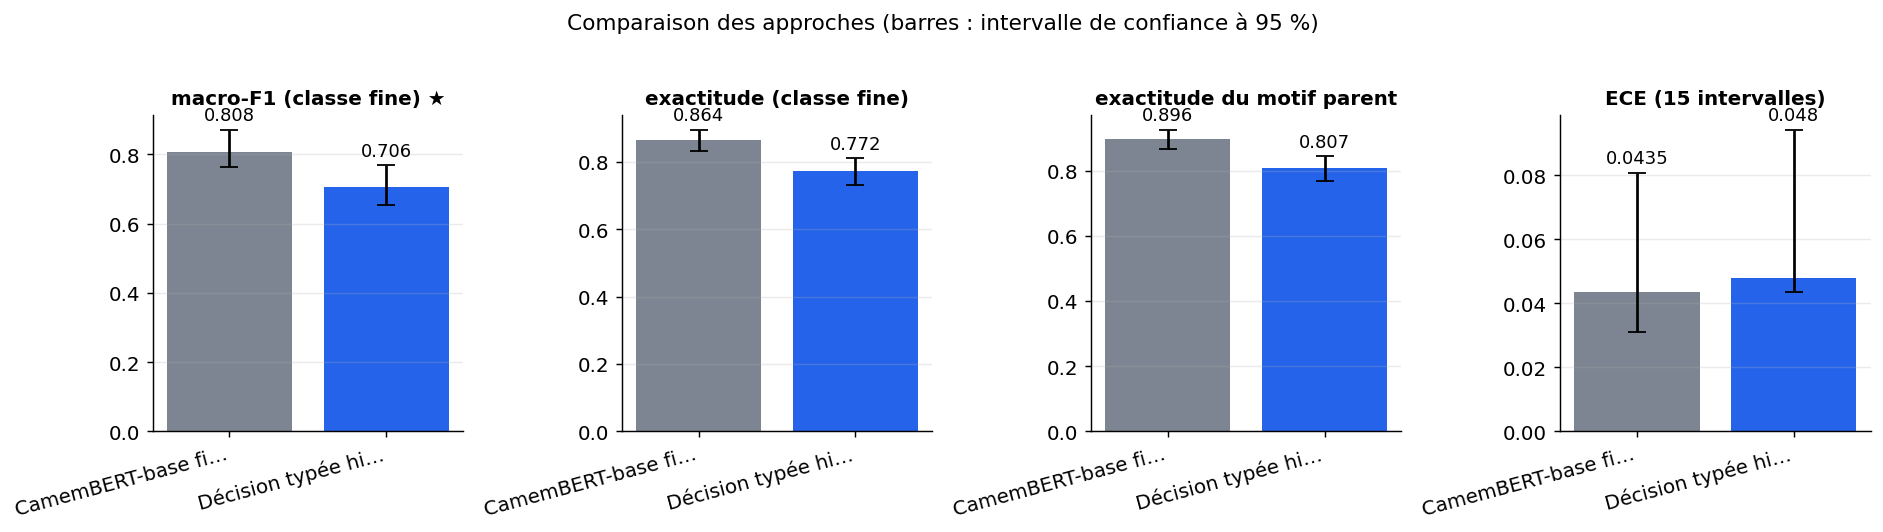

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à maximiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 404 exemples de test.*

In [44]:
METRIC_LABELS = {
    "macro_f1": "macro-F1 (classe fine)",
    "accuracy": "exactitude (classe fine)",
    "parent_accuracy": "exactitude du motif parent",
    "parent_error_rate": "part des erreurs de motif parent",
    "expected_calibration_error": "ECE (15 intervalles)",
    "brier_score": "score de Brier multiclasse",
    "permutation_agreement": "accord sous permutation des options",
    "p95_latency_ms": "latence P95 (ms, lot de 1)",
}
scorer_kind = ("substitut, probabilité des lettres" if isinstance(new_scorer, LogLikelihoodScorer)
               else f"modèle de décision via le runtime qev de OneJev ({RUNTIME_COMMIT[:10]}, serve.patch), {new_scorer.report}")
results = save_results({
    "primary_metric": "macro_f1", "direction": "max", "metric_labels": METRIC_LABELS,
    "dataset": {**DATASET_INFO, "n_examples": int(len(test))},
    "approaches": [
        {"name": "CamemBERT-base fine-tuné", "role": "reference", "metrics": reference_metrics,
         "ci95": reference_ci, "latency_ms": reference_latency,
         "notes": (f"{len(train)} exemples, {EPOCHS} époque(s), époque retenue {best_epoch}, "
                   f"température {reference_temperature:.2f}, {device()}")},
        {"name": f"Décision typée hiérarchique ({new_scorer.name})", "role": "new", "metrics": new_metrics,
         "ci95": new_ci, "latency_ms": new_latency,
         "notes": (f"{scorer_kind}, zéro-shot ; {evaluated_messages} messages évalués sur {planned_messages} prévus ({stop_reason}) ; "
                   f"motifs détaillés : {TOP_PARENTS or 'tous'} ; "
                   f"T motif {new_parent_temperature:.2f}, T sous-motif {new_child_temperature:.2f} ; "
                   f"réponses illisibles {unreadable_rate:.2%} ; {device()}")},
    ],
})
display(results_table(results))
plot_comparison(results, metrics=["macro_f1", "accuracy", "parent_accuracy", "expected_calibration_error"])

### Tests appariés : l'écart est-il réel ?
Les deux approches classent **les mêmes messages**, ce qui permet de comparer exemple par exemple :
- **bootstrap apparié** sur la différence de macro-F1 (nouvelle moins référence) : intervalle à 95 % et p-valeur bilatérale ;
- **test de McNemar** sur l'exactitude : il ne retient que les messages où une seule des deux approches a raison. Si ces cas se répartissent à peu près moitié-moitié, l'écart d'exactitude peut être dû au hasard.

In [45]:
def paired_macro_f1_test(reference_pred: np.ndarray, new_pred: np.ndarray, targets: np.ndarray):
    """Différence de macro-F1 (nouvelle - référence), intervalle bootstrap apparié et p-valeur bilatérale."""
    def macro_f1(y_true, y_pred) -> float:
        """Macro-F1 d'une série de prédictions (0 pour une classe jamais prédite)."""
        return f1_score(y_true, y_pred, average="macro", zero_division=0)

    rng = np.random.default_rng(SEED)
    observed = macro_f1(targets, new_pred) - macro_f1(targets, reference_pred)
    differences = []
    for _ in range(BOOTSTRAP_SAMPLES):
        sample = rng.integers(0, len(targets), len(targets))  # mêmes messages pour les deux approches
        differences.append(macro_f1(targets[sample], new_pred[sample]) - macro_f1(targets[sample], reference_pred[sample]))
    differences = np.asarray(differences)
    p_value = min(1.0, 2 * min(np.mean(differences <= 0), np.mean(differences >= 0)))
    return observed, np.quantile(differences, 0.025), np.quantile(differences, 0.975), p_value


reference_pred, new_pred = reference_probs.argmax(axis=1), new_probs.argmax(axis=1)
difference, low, high, bootstrap_p = paired_macro_f1_test(reference_pred, new_pred, test_targets)
only_reference = int(np.sum((reference_pred == test_targets) & (new_pred != test_targets)))
only_new = int(np.sum((reference_pred != test_targets) & (new_pred == test_targets)))
mcnemar_p = binomtest(min(only_reference, only_new), only_reference + only_new, 0.5).pvalue if only_reference + only_new else 1.0
display(pd.DataFrame({
    "valeur": [difference, low, high, bootstrap_p, only_reference, only_new, mcnemar_p]},
    index=["écart de macro-F1 (nouvelle - référence)", "IC 95 % bas", "IC 95 % haut", "p-valeur (bootstrap apparié)",
           "messages justes pour la référence seule", "messages justes pour la nouvelle seule",
           "p-valeur (McNemar exact)"]).round(4))

,valeur
écart de macro-F1 (nouvelle - référence),-0.1017
IC 95 % bas,-0.1651
IC 95 % haut,-0.0465
p-valeur (bootstrap apparié),0.0000
messages justes pour la référence seule,48.0000
messages justes pour la nouvelle seule,11.0000
p-valeur (McNemar exact),0.0000


## 6. Analyse des résultats

### Diagramme de fiabilité : la confiance annoncée est-elle tenue ?
On range les messages par **confiance annoncée** (probabilité de la classe choisie), en 15 tranches, puis on trace la **justesse observée** dans chaque tranche. Un modèle bien calibré suit la diagonale ; une courbe sous la diagonale signale un modèle trop sûr de lui.
- À gauche, les probabilités brutes ($T = 1$) : c'est là que se teste l'affirmation de la source, « calibré par construction ».
- À droite, après recalibration par température.

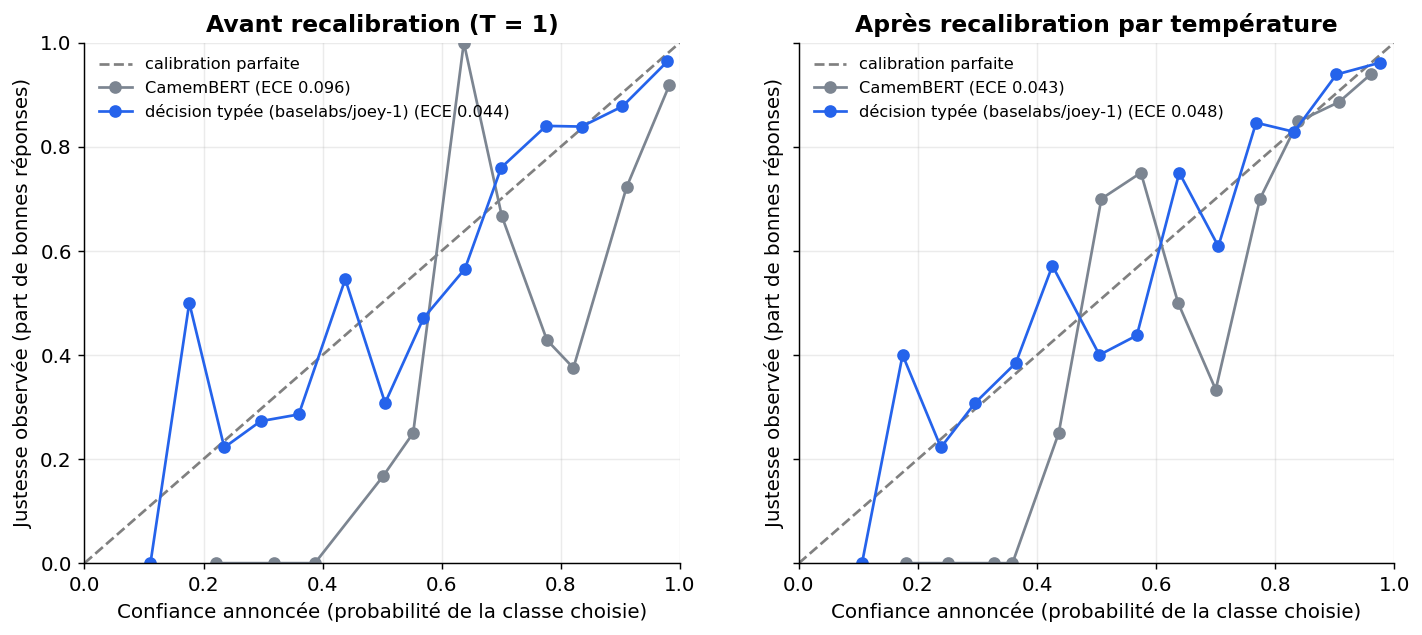

*Figure — Justesse observée selon la confiance annoncée, avant (gauche) et après (droite) recalibration. Sous la diagonale : modèle trop sûr de lui. L'ECE résume l'écart moyen à la diagonale.*

In [46]:
def reliability_points(probs: np.ndarray, targets: np.ndarray, n_bins: int = ECE_BINS) -> np.ndarray:
    """(confiance moyenne, justesse observée) pour chaque tranche de confiance non vide."""
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == targets
    bins = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    return np.array([(confidence[bins == b].mean(), correct[bins == b].mean()) for b in range(n_bins) if np.any(bins == b)])


new_name = f"décision typée ({new_scorer.name})"
panels = (("Avant recalibration (T = 1)", reference_raw_probs, new_raw_probs),
          ("Après recalibration par température", reference_probs, new_probs))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, (title, ref_probs, new_panel_probs) in zip(axes, panels):
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="calibration parfaite")
    for probs, name, color in ((ref_probs, "CamemBERT", COLORS["reference"]), (new_panel_probs, new_name, COLORS["new"])):
        points = reliability_points(probs, test_targets)
        ece = expected_calibration_error(probs, test_targets)
        ax.plot(points[:, 0], points[:, 1], marker="o", color=color, label=f"{name} (ECE {ece:.3f})")
    ax.set(title=title, xlabel="Confiance annoncée (probabilité de la classe choisie)",
           ylabel="Justesse observée (part de bonnes réponses)", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=9)
save_figure(fig, "reliability",
            "Justesse observée selon la confiance annoncée, avant (gauche) et après (droite) recalibration. "
            "Sous la diagonale : modèle trop sûr de lui. L'ECE résume l'écart moyen à la diagonale.")

### Où se situent les erreurs ? Justesse par motif parent
Pour chaque motif, on mesure la part de messages correctement classés au niveau fin. Un motif où le modèle de décision s'effondre alors que CamemBERT tient signale souvent des **libellés peu parlants** : le modèle zéro-shot ne voit que le libellé, alors que CamemBERT a vu des exemples.

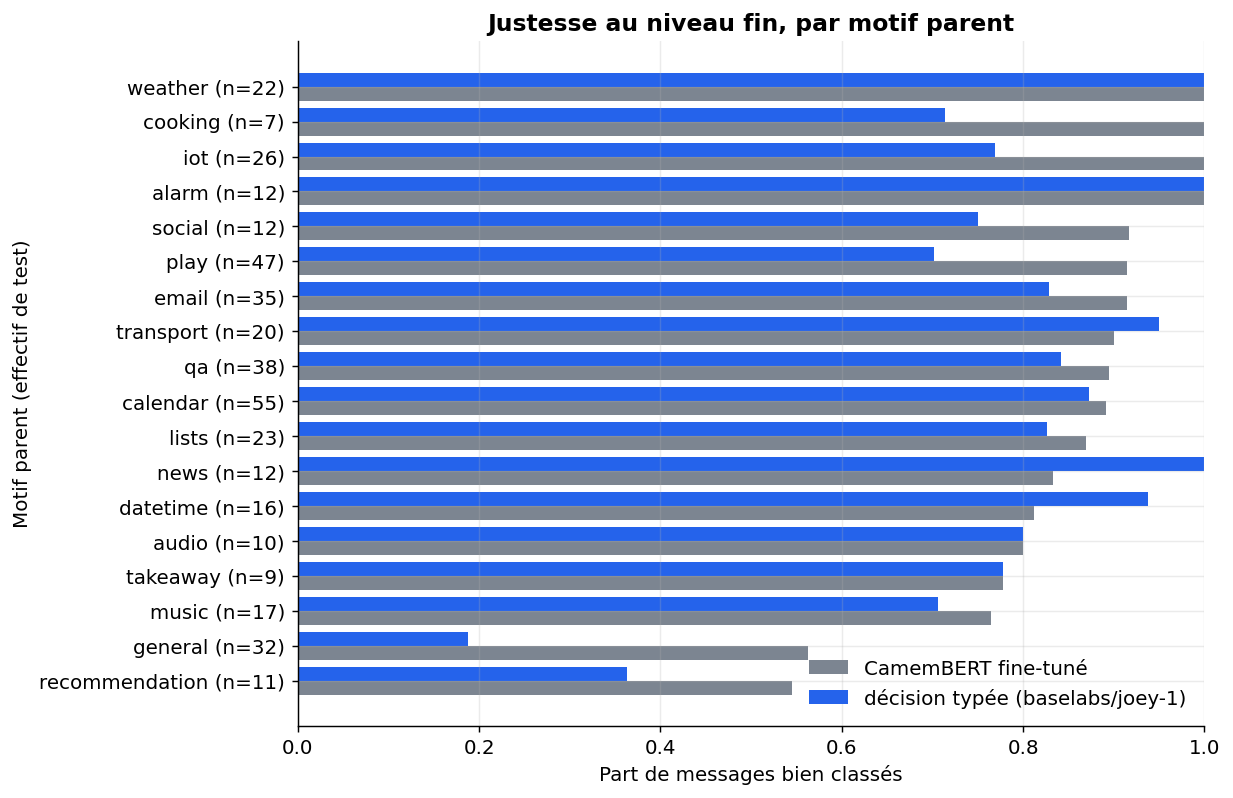

*Figure — Part de messages bien classés au niveau fin, pour chaque motif parent et chaque approche. Les motifs à faible effectif (n) donnent des barres peu stables.*

In [47]:
per_parent = pd.DataFrame({
    "parent": test["parent"].to_numpy(),
    "reference": reference_probs.argmax(axis=1) == test_targets,
    "new": new_probs.argmax(axis=1) == test_targets,
}).groupby("parent").agg(reference=("reference", "mean"), new=("new", "mean"), messages=("new", "size"))
per_parent = per_parent.sort_values("reference")

fig, ax = plt.subplots(figsize=(9, max(4.0, 0.38 * len(per_parent))))
positions = np.arange(len(per_parent))
ax.barh(positions - 0.2, per_parent["reference"], height=0.4, color=COLORS["reference"], label="CamemBERT fine-tuné")
ax.barh(positions + 0.2, per_parent["new"], height=0.4, color=COLORS["new"], label=new_name)
ax.set_yticks(positions, [f"{name} (n={count})" for name, count in zip(per_parent.index, per_parent["messages"])])
ax.set(title="Justesse au niveau fin, par motif parent", xlabel="Part de messages bien classés",
       ylabel="Motif parent (effectif de test)", xlim=(0, 1))
ax.legend(loc="lower right")
save_figure(fig, "per_parent_accuracy",
            "Part de messages bien classés au niveau fin, pour chaque motif parent et chaque approche. "
            "Les motifs à faible effectif (n) donnent des barres peu stables.")

### Biais d'ordre : le modèle préfère-t-il certaines positions ?
Pour chaque ordre pris seul, on compare la **position** du motif choisi par le modèle avec celle du **bon motif**. Sans biais, les barres suivent la ligne. Un pic sur les premières ou les dernières positions trahit une préférence de position, que la moyenne sur deux ordres cherche à neutraliser.

Le tableau donne aussi l'**accord restreint aux messages bien classés**, ce qui permet de savoir si l'instabilité touche surtout les cas déjà difficiles.

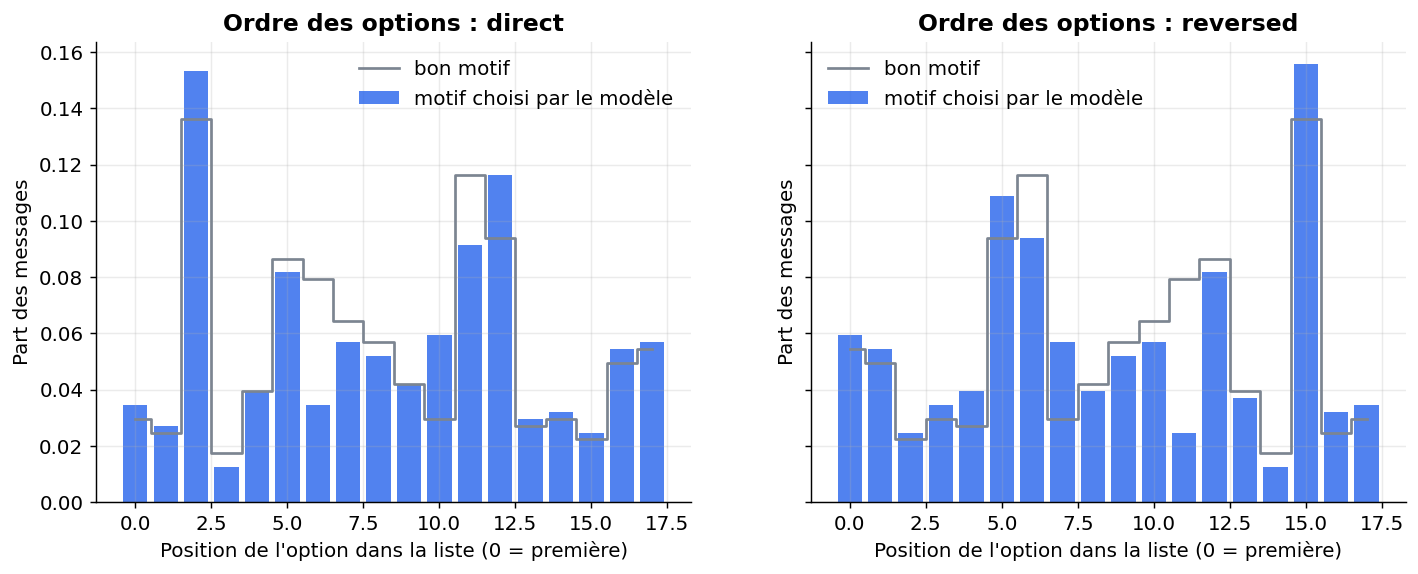

*Figure — Position, dans la liste présentée, du motif choisi (barres) et du bon motif (ligne), pour l'ordre direct et l'ordre inversé. Un écart systématique sur une position révèle un biais d'ordre.*

,valeur
accord des trois ordres (tous),0.921
accord des trois ordres (bien classés),0.962
accord des trois ordres (mal classés),0.783
accord direct / inversé,0.953


In [48]:
true_parent_indices = [parents.index(parent) for parent in test["parent"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, order in zip(axes, MAIN_ORDERS):
    chosen = np.bincount(greedy[order][:, 1], minlength=len(parents)) / len(test)
    expected = np.bincount([presented_position(i, order) for i in true_parent_indices], minlength=len(parents)) / len(test)
    ax.bar(np.arange(len(parents)), chosen, color=COLORS["new"], alpha=0.8, label="motif choisi par le modèle")
    ax.step(np.arange(len(parents)), expected, where="mid", color=COLORS["reference"], label="bon motif")
    ax.set(title=f"Ordre des options : {order}", xlabel="Position de l'option dans la liste (0 = première)",
           ylabel="Part des messages")
    ax.legend()
save_figure(fig, "position_bias",
            "Position, dans la liste présentée, du motif choisi (barres) et du bon motif (ligne), "
            "pour l'ordre direct et l'ordre inversé. Un écart systématique sur une position révèle un biais d'ordre.")

correct = new_probs.argmax(axis=1) == test_targets
direct_vs_reversed = greedy["direct"][:, 0] == greedy["reversed"][:, 0]
display(pd.DataFrame({"valeur": [
    new_agreement.mean(), new_agreement[correct].mean() if correct.any() else np.nan,
    new_agreement[~correct].mean() if (~correct).any() else np.nan, direct_vs_reversed.mean()]},
    index=["accord des trois ordres (tous)", "accord des trois ordres (bien classés)",
           "accord des trois ordres (mal classés)", "accord direct / inversé"]).round(3))

### Exemples d'erreurs (phase publique seulement)
Quelques messages mal classés par le modèle de décision, avec sa confiance et la réponse de CamemBERT. Une erreur prononcée **avec une forte confiance** est la plus dangereuse, car un seuil d'escalade ne la rattraperait pas. En phase interne, rien n'est affiché ici.

In [49]:
if PHASE == "public":
    error_table = pd.DataFrame({
        "message": test["text"].to_numpy(),
        "classe attendue": test["label"].to_numpy(),
        "décision typée": [classes[i] for i in new_probs.argmax(axis=1)],
        "confiance (décision typée)": new_probs.max(axis=1).round(3),
        "CamemBERT": [classes[i] for i in reference_probs.argmax(axis=1)],
    })[new_probs.argmax(axis=1) != test_targets]
    display(error_table.sort_values("confiance (décision typée)", ascending=False).head(10))

,message,classe attendue,décision typée,confiance (décision typée),CamemBERT
119,puis-je avoir une liste d'hôtels cinq étoiles ...,qa_factoid,recommendation_locations,0.991,recommendation_locations
93,dites-moi mon calendrier pour plus tard cet ap...,calendar_query,calendar_set,0.975,calendar_set
372,s'il vous plaît dites-moi des nouvelles liées ...,qa_stock,news_query,0.970,news_query
87,quels sont le parc d'attractions à proximité,recommendation_events,recommendation_locations,0.967,recommendation_locations
277,nouvelles mises à jour,social_query,news_query,0.960,news_query
247,je voudrais un burger au fromage,cooking_recipe,takeaway_order,0.936,cooking_recipe
81,olly je prends jour de congé demain,general_quirky,calendar_query,0.915,general_quirky
129,est-ce vendredi,calendar_query,datetime_query,0.889,calendar_query
22,où puis-je prendre un verre de tequila et d'au...,takeaway_query,recommendation_locations,0.868,recommendation_locations
364,démarre ma playlist sur nrj,play_radio,play_music,0.862,play_radio


### À retenir
- **Justesse** : si l'écart de macro-F1 avec CamemBERT dépasse 5 points et que son intervalle apparié exclut zéro, le zéro-shot ne remplace pas un classifieur fine-tuné sur ces intentions françaises. Il peut au mieux servir de premier tri, ou de solution d'attente pour les classes sans exemples.
- **Calibration** : comparez l'ECE avant et après recalibration. Si l'ECE brute est élevée et que la température s'éloigne nettement de 1, l'affirmation « calibré par construction » ne se vérifie pas ici. Tout seuil d'escalade doit alors être fixé sur des données internes, jamais sur la confiance brute.
- **Stabilité** : un accord sous permutation inférieur à 90 %, ou un pic sur certaines positions, rend indispensable la moyenne sur plusieurs ordres, ce qui double le coût par message.
- **Erreurs de motif** : si la part des erreurs de motif dépasse 20 %, les erreurs du modèle de décision envoient les messages dans la mauvaise file, et non dans un sous-motif voisin. C'est le cas le plus coûteux en routage.
- À l'échelle réduite, les chiffres viennent d'un substitut et d'une référence sous-entraînée : ils valident le code et le chemin de joey-1 (sans les poids, puis sur un micro-modèle), **pas** la conclusion.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle complète (GPU T4, 404 énoncés de test sur 1500 prévus, mêmes messages pour les deux approches), CamemBERT-base bien réglé obtient un macro-F1 de 0,81 contre 0,71 pour joey-1 en zéro-shot hiérarchique. L'écart de −10,2 points (intervalle −16,5 à −4,7) rejette l'hypothèse « à moins de 5 points ». L'exactitude suit (0,86 contre 0,77), et McNemar donne 48 messages justes pour la référence seule contre 11. La calibration après recalibration (ECE 0,048 contre 0,043) et l'accord sous permutation (0,92) sont proches des seuils, mais non tranchés vu les intervalles. Le Brier est moins bon (0,33 contre 0,22), et la latence de 8,2 s contre 14 ms ne se compare pas au 20 ms de la fiche. Les chiffres de l'échelle réduite (substitut, micro-modèle) ne valent que pour le code. Conclusion indicative : jeu d'assistant vocal, hors services financiers, langue française.

*Échelle complète : 404 exemples de test de `mteb/amazon_massive_intent` (GPU T4 (Google Colab), 83 min). La mécanique avait d'abord été validée à l'échelle réduite (100 exemples, CPU).*

| Approche | macro-F1 (classe fine) ★ ↑ | exactitude (classe fine) ↑ | exactitude du motif parent ↑ | part des erreurs de motif parent ↓ | ECE (15 intervalles) ↓ | score de Brier multiclasse ↓ | accord sous permutation des options ↑ | latence P95 (ms, lot de 1) ↓ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|---|
| CamemBERT-base fine-tuné (référence) | **0,808 [0,765 ; 0,871]** | **0,864 [0,832 ; 0,896]** | **0,896 [0,866 ; 0,926]** | **0,764 [0,65 ; 0,879]** | **0,0435 [0,0311 ; 0,0808]** | **0,223 [0,173 ; 0,279]** | — | **17** | 14,3 |
| Décision typée hiérarchique (baselabs/joey-1) (nouvelle approche) | 0,706 [0,653 ; 0,769] | 0,772 [0,73 ; 0,812] | 0,807 [0,767 ; 0,844] | 0,848 [0,768 ; 0,916] | 0,048 [0,0436 ; 0,0942] | 0,332 [0,281 ; 0,382] | 0,921 [0,896 ; 0,946] | 8,25e+03 | 8,22e+03 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Les chiffres reposent sur 404 énoncés, soit environ un quart du test prévu. Les écarts fins (calibration, accord sous permutation) ne sont pas tranchés ; seul l'écart de justesse est net.
- La calibration et la stabilité de joey-1 sont compatibles avec les seuils visés, mais pas démontrées : l'incertitude couvre les deux côtés. Le score de Brier, lui, est nettement moins bon que celui de la référence.
- Le chiffre de « part des erreurs de motif » ne se compare pas au seuil de 20 %. Sur l'ensemble des messages, joey-1 se trompe de motif environ une fois sur cinq, contre environ une fois sur dix pour CamemBERT.
- Le rapport de latence d'environ 500 contre CamemBERT vient surtout du protocole hiérarchique à une trentaine de questions sur un GPU modeste. Il ne contredit ni ne confirme le 20 ms annoncé.

**Limites**

- MASSIVE (énoncés vocaux très courts, 60 classes, libellés en anglais posés à un modèle documenté en anglais seulement) diffère des messages internes en services financiers : la conclusion reste indicative.
- Le nombre de messages réellement évalués dépend du GPU et du budget de temps : il est donné dans les résultats, et des intervalles plus larges sont à attendre s'il est loin des 1 500 prévus.
- `causal-conv1d`, prévu par le `setup.sh` du modèle, n'est pas installé : son calcul de référence, `F.conv1d`, est le même. `triton` n'est installé que sur le GPU (`triton==3.6.0`, absent de `requirements.txt`) ; le rapport d'exécution conservé avec les résultats indique le noyau d'attention linéaire réellement utilisé.
- En phase private, le runtime OneJev corrigé et le dossier du modèle, poids compris, doivent être préparés à l'avance, faute d'accès à Internet. Si tout le test tient dans `TEST_SIZE`, ses premiers messages sont les plus anciens : le budget de temps doit alors couvrir tout le test, sinon l'échantillon évalué n'est plus aléatoire.
- Les températures du modèle de décision sont ajustées sur un sous-échantillon de validation (500 messages), et la confiance mesure la concentration des probabilités, pas la justesse : tout seuil d'escalade doit être validé sur données internes.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, la référence est entraînée sur 1 000 exemples pendant 1 époque, et la validation compte 300 messages (24 pour les températures du modèle de décision). 110 messages de test sont prévus, et la boucle s'arrête à 100 pour exercer l'arrêt anticipé. joey-1 est remplacé par le substitut Qwen/Qwen3-0.6B, qui note les options par la probabilité de leur lettre et ne détaille que le motif le plus probable. Ce n'est pas un modèle de décision : il ne sert qu'à valider le code. Le vrai chemin de joey-1 (runtime épinglé, requête, lecture, contrôles d'attention, modes batched et sequential, protocole complet) est répété sur un micro-modèle de même architecture à poids aléatoires. Ses réponses ne mesurent rien.

**Améliorations possibles**

- L'écart avec CamemBERT est probablement un peu pessimiste pour joey-1 (libellés pauvres, langue non prévue). Une éventuelle présence de MASSIVE dans ses données d'entraînement jouerait en sens inverse.
- La mesure ne dit rien sur la capacité de joey-1 à s'abstenir. Le seuil d'escalade reste à valider sur des données internes.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).